# 03 — Preprocessing du dataset pour le Supervised Learning (version finale)

**Objectif.** Transformer la grille ERA5-Land masquée (sortie du notebook 01, analysée dans le notebook 02 — EDA) en un dataset **prêt à l'emploi** pour l'apprentissage supervisé : prédire la **classe de température à 2 m du mois M+1** (3 intervalles de même largeur) à partir des variables du mois M.

**Continuité avec l'EDA (notebook 02).** Ce notebook reprend les mêmes noms (`BASE`, `ALL`, `LABELS`, `UNITS`), la même conversion d'unités et la même structure de tableau (1 ligne = cellule × mois), mais il **ne refait pas l'EDA** : ses constats sont repris tels quels. On ne recalcule que ce qui **change à cause d'une décision de prétraitement** (données corrigées, Train seul, variables transformées), pour montrer l'effet de chaque décision.

| Déjà fait dans le notebook 02 → **non refait ici** | Référence |
|---|---|
| Tableau des NaN / zéros, carte des cellules du domaine, contrôle sur la grille brute (12 cellules sans donnée) | EDA §1.1 |
| Valeurs uniques, tableau de variance (unités, Min-Max, % de variance temporelle) | EDA §1.2, §1.3 |
| Statistiques descriptives, histogrammes et boxplots des variables brutes, test de Shapiro-Wilk | EDA §2, §5.1 |
| Séries régionales brutes | EDA §3 |
| Matrices de corrélation Pearson et Spearman (données brutes, toute la période) | EDA §5.1 |
| Cartes de la moyenne temporelle non corrigée | EDA §6 |

### Remarques de l'EDA → traitement retenu

| Remarque de l'enseignante | Ce que montre l'EDA | Traitement (section) |
|---|---|---|
| **Valeurs manquantes** à la frontière nord | 12 cellules de la grille brute dans le polygone sans aucune donnée (points mer d'ERA5-Land) ; **0 NaN** dans le domaine après réduction 2×2 | Contrôle + exclusion des cellules hors domaine, **aucune imputation** ; imputation spatiale prévue seulement en secours (§1) |
| **Variabilité** très faible de certaines features | Variance < 0,01 : `ro` (unités) ; Min-Max < 0,01 : `slhf`, `ro`, `e`, `tp` ; `sp` : ≈ 1 % de variance temporelle | `ro` supprimée ; `slhf`, `tp` conservées (effet d'échelle corrigé par le log) ; `sp` conservée (proxy d'altitude) (§6, §7) |
| **Histogrammes / boxplots** : features très asymétriques, grande proportion d'« outliers » | skew : `ro` 45,2 ; `tp` 5,8 ; `slhf`/`e` −4,2 ; 15–16 % d'outliers IQR | Aucune suppression (extrêmes climatiques réels) ; contrôle physique (§3) ; **log signé** décidé sur le Train (§7) |
| **Variation mensuelle** : incohérences entre 2022 et 2024 | Variables **accumulées** ≈ divisées par 2 pendant 18 mois ; variables instantanées normales | *Known issue* ECMWF (sept. 2022 → févr. 2024) → **correction multiplicative** (§2) |
| **Matrice de corrélation** : fortes corrélations (bonne formule) | `slhf`–`e` = 1,000 ; `ro`–`tp` = 0,980 ; `ssr`–`sshf` = −0,948 (**Spearman**, aucune variable normale) | `e` et `ro` supprimées ; `ssr`/`sshf` conservées après test sur les anomalies (§6) |

## Ordre du pipeline et justification

| # | Étape | Pourquoi à cet endroit |
|---|---|---|
| 1 | Complétude de la grille, axe temporel | Tout ce qui suit suppose une grille complète et un axe mensuel continu (le décalage M+1 en dépend). |
| 2 | Correction de l'artefact ERA5-Land 2022-2024 | Erreur **de source** : elle fausse toutes les statistiques en aval (asymétrie, quartiles, corrélations, moyennes du scaler). Elle est corrigée **en premier**. Correction **déterministe** (mois documentés + facteur constant estimé sur des mois du Train) → aucune fuite. |
| 3 | Cohérence physique, décision sur les outliers | Après la correction, sinon les 18 mois corrigés apparaîtraient comme anormaux à tort. |
| 4 | Tableau d'échantillons + **cible M+1** | La cible se construit sur la grille complète et ordonnée, **avant** toute séparation, pour que chaque cellule garde sa continuité temporelle. |
| 5 | **Split chronologique** | Doit précéder **toute** étape qui *apprend* quelque chose des données (sélection, seuils, scaler). |
| 6 | Sélection des features (redondance, faible variabilité) | Décidée sur le **Train uniquement**. Spearman est invariant aux transformations monotones : l'ordre 6 → 7 ne change pas la décision de redondance. |
| 7 | Transformation des asymétries (log signé) | Après la sélection (inutile de transformer une variable supprimée), avant le scaling (le scaler doit voir les données transformées). La liste des variables à transformer est décidée sur le Train ; la formule est sans paramètre. |
| 8 | Feature extraction (encodage cyclique du mois) | Transformation sans paramètre, avant le scaling. |
| 9 | Discrétisation de la cible (equal-width, 3 classes) | Bornes calculées sur le **Train**, appliquées au Test. |
| 10 | Analyse des classes | Une fois les classes définies. |
| 11 | Feature scaling | **Dernière** transformation : `fit` sur le Train, `transform` du Test. |
| 12-13 | Export + vérifications sur les fichiers relus | — |

## 0. Chargement, configuration et conversion des unités

In [1]:
from pathlib import Path
import json, warnings
from datetime import datetime
import numpy as np, pandas as pd, xarray as xr
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
import joblib
from sklearn.preprocessing import StandardScaler
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)
plt.style.use("seaborn-v0_8-whitegrid")            # même style que l'EDA
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40)
SEED = 42
RNG = np.random.default_rng(SEED)

DATA_REL = Path("data") / "processed" / "era5_algeria_masked_2x2_v2.nc"
_here = Path.cwd().resolve()
PROJECT_ROOT = next((p for p in [_here, *_here.parents] if (p / DATA_REL).exists()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError(f"{DATA_REL} introuvable : exécutez d'abord le notebook 01.")
OUT_DIR = PROJECT_ROOT / "data" / "supervised"      # dossier dédié : les données d'origine ne sont jamais écrasées
OUT_DIR.mkdir(parents=True, exist_ok=True)

ds = xr.open_dataset(PROJECT_ROOT / DATA_REL).load()
print("Fichier    :", PROJECT_ROOT / DATA_REL)
print("Dimensions :", dict(ds.sizes))
print("Sorties    :", OUT_DIR)

Fichier    : C:\Users\hp\Downloads\Climate_Data_Mining_Algeria\Climate_Data_Mining_Algeria\Climate_Data_Mining\data\processed\era5_algeria_masked_2x2_v2.nc
Dimensions : {'valid_time': 141, 'latitude': 95, 'longitude': 105}
Sorties    : C:\Users\hp\Downloads\Climate_Data_Mining_Algeria\Climate_Data_Mining_Algeria\Climate_Data_Mining\data\supervised


In [2]:
# ---------------- Variables : mêmes noms que l'EDA ----------------
BASE = ["d2m","t2m","slhf","ssr","str","sshf","ro","e","u10","v10","sp","tp"]
ALL  = BASE + ["wind10_speed"]
ACCUMULATED = ["slhf","ssr","str","sshf","ro","e","tp"]      # variables accumulées ERA5-Land (Table 3 de la doc)
LABELS = {"d2m":"Point de rosee 2 m (°C)","t2m":"Temperature 2 m (°C)","slhf":"Flux chaleur latente (W/m²)",
          "ssr":"Rayonnement solaire net (W/m²)","str":"Rayonnement thermique net (W/m²)","sshf":"Flux chaleur sensible (W/m²)",
          "ro":"Ruissellement (mm/j)","e":"Evaporation (mm/j)","u10":"Vent u10 (m/s)","v10":"Vent v10 (m/s)",
          "sp":"Pression surface (hPa)","tp":"Precipitation (mm/j)","wind10_speed":"Vitesse du vent 10 m (m/s)"}
UNITS = {"d2m":"°C","t2m":"°C","slhf":"W/m²","ssr":"W/m²","str":"W/m²","sshf":"W/m²",
         "ro":"mm/j","e":"mm/j","tp":"mm/j","u10":"m/s","v10":"m/s","wind10_speed":"m/s","sp":"hPa"}

# ---------------- Interrupteurs de décision (modifiables sans toucher au reste) ----------------
USE_WIND_SPEED = True    # vitesse du vent = feature dérivée déjà introduite par l'EDA
USE_YEAR       = True    # `year` fait partie des features du sujet ; voir la mise en garde en §8 et §11
MANUAL_DROP    = []      # ex. ["sshf"] pour forcer le retrait d'une variable en plus des règles de la §6

# ---------------- Paramètres ----------------
AFFECTED = pd.date_range("2022-09-01", "2024-02-01", freq="MS")     # période documentée par l'ECMWF (18 mois)
REF_YEARS = (2015, 2021)                                            # climatologie de référence : années saines, toutes dans le Train
SPLIT_TARGET = pd.Timestamp("2024-01-01")                           # Train : mois CIBLE < 2024-01 ; Test : mois cible >= 2024-01
LAST_TRAIN_FEATURE = SPLIT_TARGET - pd.DateOffset(months=2)         # dernier mois M (features) du Train = 2023-11
CLASS_LABELS = ["Froid", "Modere", "Chaud"]                         # mêmes libellés que l'EDA
CORR_THRESHOLD = 0.90                                               # cours 04 : corrélation > 90 %
LOWVAR_THRESHOLD = 0.01                                             # cours 04 : variance < 0.01
CAND = [v for v in ALL if v != "t2m" and (USE_WIND_SPEED or v != "wind10_speed")]   # features candidates (t2m ne sert qu'à la cible)

# ---------------- Journal de traçabilité (repris dans le JSON exporté) ----------------
LOG = []
def log_step(step, decision, **details):
    LOG.append({"etape": step, "decision": decision, **details}); print(f"[LOG] {step} → {decision}")

# ---------------- Conversion des unités (identique à l'EDA, cellule 3) ----------------
assert all(v in ds.data_vars for v in BASE), "Variables absentes du fichier"
conv = xr.Dataset(coords=ds.coords)
for v in ["d2m","t2m"]:               conv[v] = ds[v] - 273.15          # K -> °C
for v in ["slhf","ssr","str","sshf"]: conv[v] = ds[v] / 86400.0         # J/m² par jour -> W/m²
for v in ["ro","e","tp"]:             conv[v] = ds[v] * 1000.0          # m par jour -> mm/j
conv["sp"] = ds["sp"] / 100.0                                           # Pa -> hPa
conv["u10"], conv["v10"] = ds["u10"], ds["v10"]
conv["wind10_speed"] = np.hypot(ds["u10"], ds["v10"])
conv = conv[ALL]

TIMES = pd.DatetimeIndex(conv.valid_time.values)
print("Période :", TIMES.min().date(), "→", TIMES.max().date(), f"({len(TIMES)} mois)")
print("Features candidates :", CAND)

Période : 2015-01-01 → 2026-09-01 (141 mois)
Features candidates : ['d2m', 'slhf', 'ssr', 'str', 'sshf', 'ro', 'e', 'u10', 'v10', 'sp', 'tp', 'wind10_speed']


## 1. Complétude de la grille — valeurs manquantes de la frontière nord

**Constat (EDA §1.1, non refait).** 12 cellules de la grille brute sont dans le polygone de l'Algérie mais n'ont **aucune** valeur sur toute la période (points mer : ERA5-Land est un produit *terre*). Après la réduction 2×2 du notebook 01 (`coarsen().mean()` ignore les NaN), il n'y a **aucun NaN** dans le domaine.

**Décision : aucune imputation.**
- Une cellule sans aucune donnée n'est pas une valeur manquante à reconstituer : c'est un point **hors du domaine terrestre**. L'imputer (moyenne, médiane, kNN…) fabriquerait un climat « terrestre » là où il n'y a pas de terre. On l'**exclut** du domaine, comme dans l'EDA.
- Les **zéros** ne sont pas des valeurs manquantes : `ro = 0` (≈ 19 % des échantillons) est une absence réelle de ruissellement au Sahara ; ils sont conservés.
- Si une autre version du masque produisait des cellules avec des mois manquants isolés, la cellule d'imputation ci-dessous remplit chaque trou par la **moyenne des cellules voisines (3×3) au même mois** (imputation « intelligente » du cours 04, variante spatiale). La moyenne globale serait fausse : elle mélangerait le Sahara et la côte.

Ici on se contente de **vérifier** que le domaine est complet (aucun tableau ni figure refaits).


In [3]:
# Domaine = au moins une valeur (même définition que l'EDA §1.1) ; ici on ne fait que le vérifier
valid_cells = conv["t2m"].notnull().any("valid_time")
vm = valid_cells.values
T, N = len(TIMES), int(vm.sum())
ilat, ilon = np.where(vm)
partial = conv.to_array().isnull().any(("variable", "valid_time")) & valid_cells
print(f"Cellules de la grille : {valid_cells.size} | dans le domaine (≥1 valeur) : {N} | hors domaine (masque) : {valid_cells.size - N}")
print("Cellules du domaine avec au moins un mois manquant :", int(partial.sum()), "(0 attendu, cf. EDA §1.1)")

Cellules de la grille : 9975 | dans le domaine (≥1 valeur) : 5424 | hors domaine (masque) : 4551
Cellules du domaine avec au moins un mois manquant : 0 (0 attendu, cf. EDA §1.1)


In [4]:
def impute_spatial_neighbours(da, max_iter=5):
    # Remplace chaque NaN du domaine par la moyenne de ses voisins 3x3 au MÊME pas de temps
    for _ in range(max_iter):
        hole = da.isnull() & valid_cells
        if not bool(hole.any()):
            break
        neigh = da.rolling(latitude=3, longitude=3, center=True, min_periods=1).mean()
        da = da.where(~hole, neigh)
    return da

if int(partial.sum()) > 0:
    for v in ALL:
        conv[v] = impute_spatial_neighbours(conv[v])
    left = int((conv.to_array().isnull().any("variable") & valid_cells).sum())
    print("→ imputation spatiale appliquée ; NaN restants dans le domaine :", left)
    log_step("1. Valeurs manquantes", "imputation spatiale 3×3 au même mois", cellules_partielles=int(partial.sum()))
else:
    print("→ aucune imputation nécessaire (conforme à l'EDA)")
    log_step("1. Valeurs manquantes", "aucune imputation ; cellules sans donnée exclues du domaine", cellules_hors_domaine=int(valid_cells.size - N))

# Intégrité de l'axe temporel (prérequis du décalage M+1)
assert (TIMES.to_period("M").to_series().diff().dropna().apply(lambda x: x.n) == 1).all(), "mois manquants"
assert TIMES.is_monotonic_increasing and TIMES.is_unique
print("Axe temporel : mensuel, continu, trié, sans doublon ✔")

→ aucune imputation nécessaire (conforme à l'EDA)
[LOG] 1. Valeurs manquantes → aucune imputation ; cellules sans donnée exclues du domaine
Axe temporel : mensuel, continu, trié, sans doublon ✔


## 2. Incohérences 2022-2024 : correction de l'artefact ERA5-Land

### 2.1 Diagnostic

**Observation (EDA §3 : variation mensuelle et Q-Q plot 2022 vs 2024).** Sur la série régionale, `ssr`, `str`, `slhf`, `sshf`, `e`, `ro` et `tp` ont des moyennes mensuelles environ **deux fois plus faibles en valeur absolue** sur un bloc de mois entre fin 2022 et début 2024 (ex. `ssr` en été ≈ 110 W/m² au lieu de ≈ 215). Les variables **instantanées** (`t2m`, `d2m`, `sp`, `u10`, `v10`) et la vitesse du vent n'ont pas ce saut.

**Pourquoi ce n'est pas un signal climatique.** Un rayonnement solaire net divisé par deux en plein été saharien, avec une température normale, est physiquement incohérent. Le saut touche **exactement** la famille des variables accumulées : c'est la signature d'une erreur de traitement.

**Source.** L'ECMWF a recensé ce problème comme *known issue* du produit *ERA5-Land monthly averaged reanalysis* : toutes les variables accumulées, **septembre 2022 → février 2024** (18 mois), sont incorrectes ; les données corrigées ne sont disponibles qu'à partir de mars 2024. Référence : *Issue affecting ERA5-Land monthly averaged reanalysis for the period September 2022 to February 2024*, forum ECMWF.

**Vérification sur nos données.** On compare la moyenne régionale de chaque mois (pondérée par cos(lat), comme dans l'EDA) à une **climatologie de référence** du même mois calendaire : la moyenne 2015-2021 (années saines, toutes dans le Train). Deux mesures :
- l'**anomalie standardisée** $z = (x - \bar{x}_{\text{mois}})/\sigma_{\text{mois}}$, calculable pour toutes les variables ;
- le **rapport** $x / \bar{x}_{\text{mois}}$, pour les variables accumulées seulement : ≈ 1 pour un mois normal, ≈ 0,5 pour un mois divisé par 2.

In [5]:
w = np.cos(np.deg2rad(conv.latitude))                           # pondération par cos(lat), comme dans l'EDA
def regional(c):
    out = pd.DataFrame({v: c[v].weighted(w).mean(("latitude", "longitude")).to_series() for v in ALL})
    out.index = pd.to_datetime(out.index)
    return out

def _clim(reg):
    ref = reg[(reg.index.year >= REF_YEARS[0]) & (reg.index.year <= REF_YEARS[1])]
    g = ref.groupby(ref.index.month)
    return g.mean().loc[reg.index.month].values, g.std().loc[reg.index.month].values
ratio_to_clim = lambda reg: reg / _clim(reg)[0]
z_to_clim = lambda reg: (reg - _clim(reg)[0]) / _clim(reg)[1]

reg_before = regional(conv)
ratio_before, z_before = ratio_to_clim(reg_before), z_to_clim(reg_before)
is_aff = ratio_before.index.isin(AFFECTED)

summary = pd.DataFrame({
    "|z| médian — mois documentés": z_before[is_aff].abs().median(),
    "|z| médian — autres mois": z_before[~is_aff].abs().median(),
    "rapport médian — mois documentés": ratio_before[is_aff].median().where(lambda s: s.index.isin(ACCUMULATED)),
    "rapport médian — autres mois": ratio_before[~is_aff].median().where(lambda s: s.index.isin(ACCUMULATED))}).round(3)
summary["accumulée ?"] = [v in ACCUMULATED for v in summary.index]
display(summary)

# Détection indépendante : mois où ssr ET str (accumulées les plus stables) sont < 75 % de la normale
flag = (ratio_before["ssr"] < 0.75) & (ratio_before["str"] < 0.75)
detected = ratio_before.index[flag]
print(f"Mois détectés dans les données : {len(detected)} ({detected.min():%Y-%m} → {detected.max():%Y-%m})" if len(detected) else "Aucun mois détecté")
print("Coïncide exactement avec la période documentée :", set(detected) == set(AFFECTED))

,|z| médian — mois documentés,|z| médian — autres mois,rapport médian — mois documentés,rapport médian — autres mois,accumulée ?
d2m,0.627,0.644,NaN,NaN,False
t2m,1.018,0.750,NaN,NaN,False
slhf,2.163,0.753,0.347,0.910,True
ssr,22.272,0.658,0.535,1.002,True
str,11.995,0.709,0.490,1.003,True
sshf,10.429,0.717,0.489,1.003,True
ro,1.217,0.739,0.145,0.691,True
e,2.163,0.753,0.347,0.910,True
u10,0.621,0.726,NaN,NaN,False
v10,0.993,0.798,NaN,NaN,False


Mois détectés dans les données : 18 (2022-09 → 2024-02)
Coïncide exactement avec la période documentée : True


### 2.2 Choix de la correction

| Option | Avantage | Inconvénient |
|---|---|---|
| **Re-télécharger** les 18 mois (produit « monthly averaged reanalysis by hour of day », contournement proposé par l'ECMWF) | Valeurs exactes | Il faut refaire l'extraction et le notebook 01 ; meilleure option si le temps le permet |
| Supprimer les 18 mois | Simple | Perd 13 % de la période et casse la continuité temporelle nécessaire à la cible M+1 |
| Traiter comme manquant + imputer par la climatologie | Conserve les lignes | Efface la variabilité interannuelle réelle (sécheresses, vagues de chaleur) alors que l'information est présente à un facteur près |
| **Correction multiplicative** | Conserve toutes les lignes **et** la variabilité réelle ; un facteur constant correspond à la nature de l'erreur | Suppose un facteur constant : vérifié ci-dessous |

**Décision : correction multiplicative.** Le facteur est estimé **uniquement sur les mois affectés qui appartiennent au Train** (sept. 2022 → nov. 2023), par rapport à la climatologie 2015-2021. Il est d'abord estimé séparément pour chaque variable accumulée, pour vérifier qu'il est **commun**. La valeur appliquée est la médiane des facteurs de `ssr` et `str`, les deux variables accumulées les plus stables d'une année à l'autre. Si elle est à moins de 0,1 de 2, on applique exactement **2** (explication la plus simple d'une erreur de traitement : valeur divisée par 2) pour ne pas ajuster du bruit.

In [6]:
est_months = AFFECTED[AFFECTED <= LAST_TRAIN_FEATURE]                  # mois affectés appartenant au Train
inv = 1.0 / ratio_before.loc[est_months, ACCUMULATED]
factors = pd.DataFrame({"facteur médian": inv.median(), "écart interquartile": inv.quantile(.75) - inv.quantile(.25)}).round(3)
display(factors.T)

f_est = float(np.median([factors.loc["ssr", "facteur médian"], factors.loc["str", "facteur médian"]]))
FACTOR = 2.0 if abs(f_est - 2.0) < 0.1 else round(f_est, 3)
inv_ss = inv[["ssr", "str"]].mean(axis=1)
print(f"Facteur estimé (ssr, str) = {f_est:.3f} → facteur appliqué = {FACTOR}")
print(f"Stabilité d'un mois à l'autre (coefficient de variation ssr/str) : {100 * inv_ss.std() / inv_ss.mean():.1f} %")

,slhf,ssr,str,sshf,ro,e,tp
facteur médian,3.085,1.864,2.043,2.044,7.204,3.085,3.806
écart interquartile,1.583,0.049,0.058,0.084,5.533,1.583,3.385


Facteur estimé (ssr, str) = 1.954 → facteur appliqué = 2.0
Stabilité d'un mois à l'autre (coefficient de variation ssr/str) : 3.1 %


[LOG] 2. Incohérences 2022-2024 → variables accumulées × 2.0 sur 18 mois (2022-09 → 2024-02)


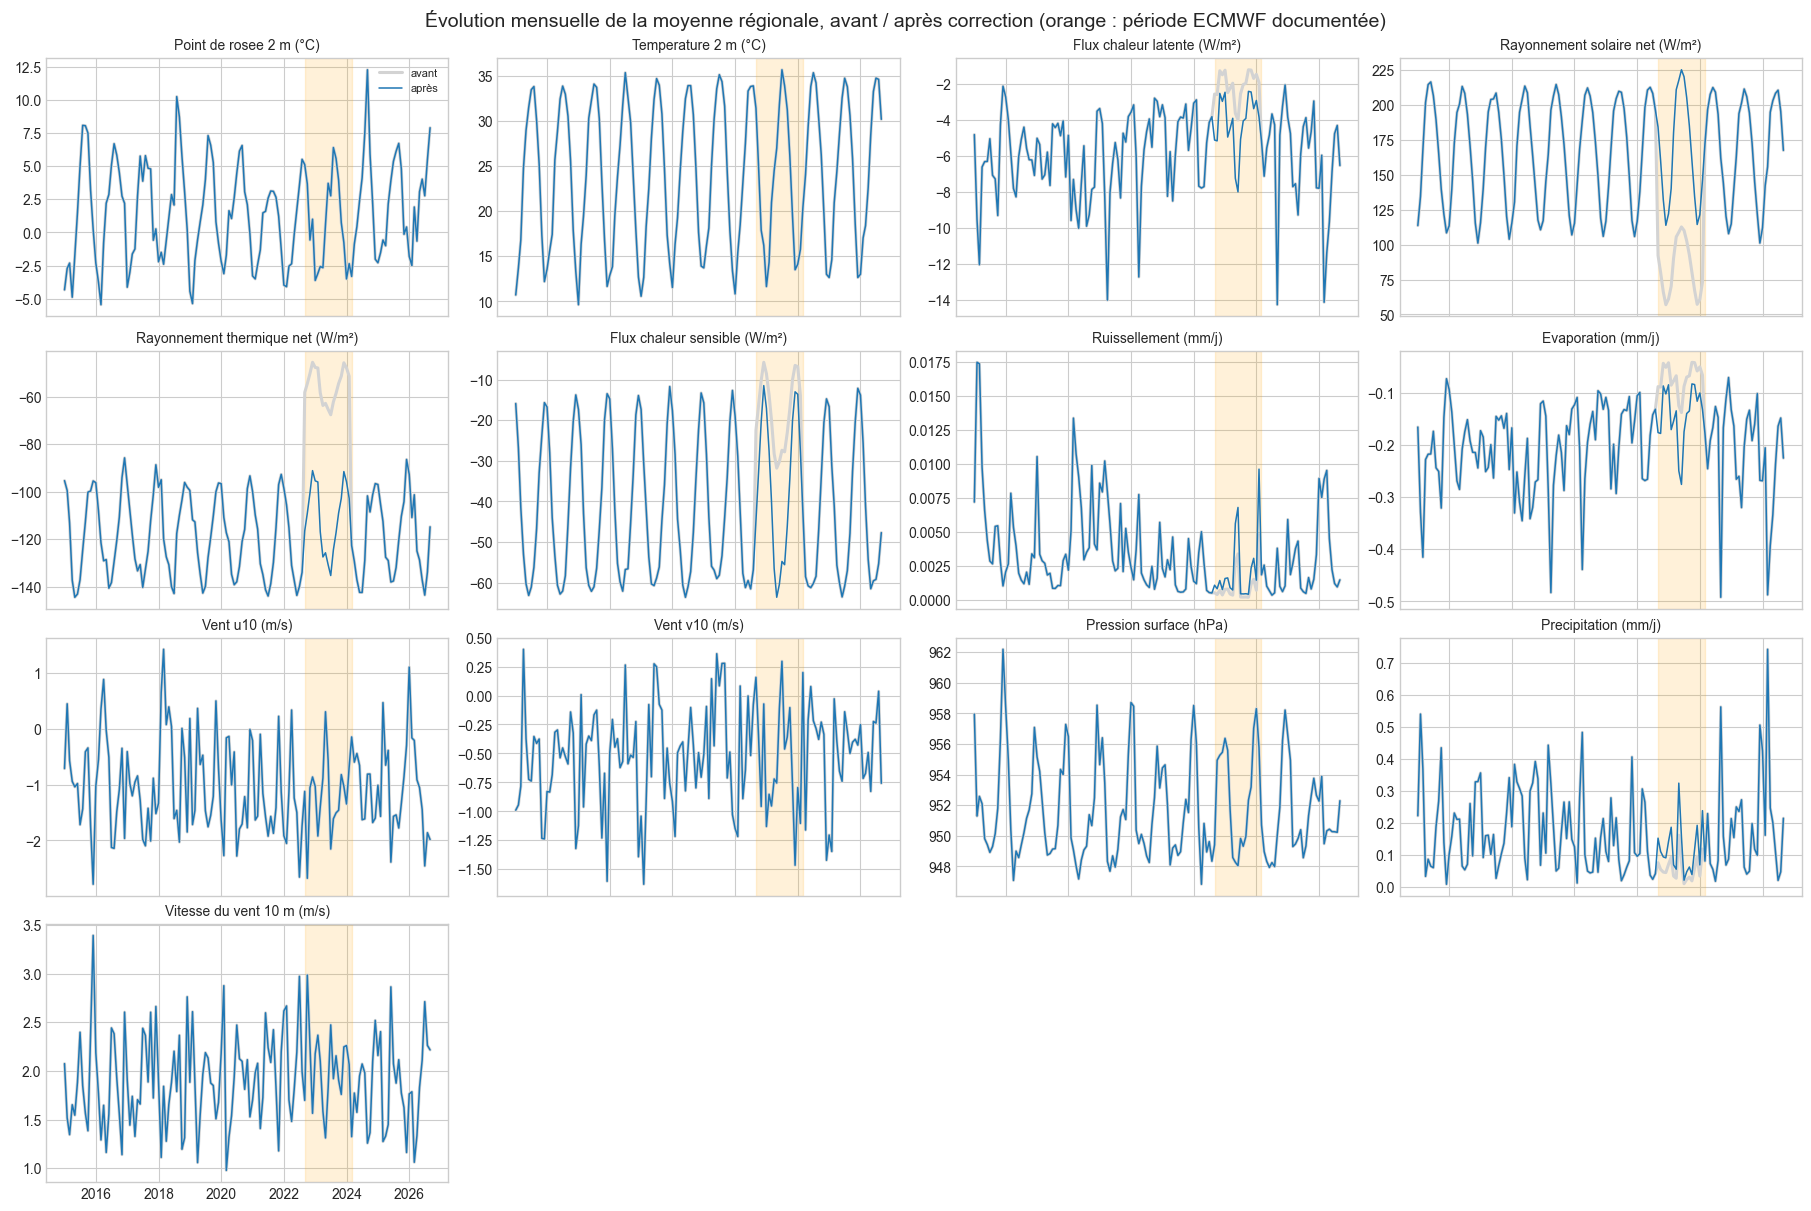

In [7]:
gridc = conv.copy()                                                    # grille corrigée (conv reste intacte pour les comparaisons)
sel = gridc.valid_time.dt.strftime("%Y-%m").isin(AFFECTED.strftime("%Y-%m"))
for v in ACCUMULATED:
    gridc[v] = xr.where(sel, conv[v] * FACTOR, conv[v])
gridc = gridc.transpose("valid_time", "latitude", "longitude")
reg_after = regional(gridc)
ratio_after, z_after = ratio_to_clim(reg_after), z_to_clim(reg_after)
log_step("2. Incohérences 2022-2024", f"variables accumulées × {FACTOR} sur {len(AFFECTED)} mois ({AFFECTED.min():%Y-%m} → {AFFECTED.max():%Y-%m})",
         variables=ACCUMULATED, facteur_estime=round(f_est, 3), source="ECMWF known issue")

# ---- Variation mensuelle de la moyenne régionale : avant / après (même figure que l'EDA §3) ----
fig, axes = plt.subplots(4, 4, figsize=(18, 12), constrained_layout=True, sharex=True)
for ax, v in zip(axes.flat, ALL):
    ax.axvspan(AFFECTED.min(), AFFECTED.max() + pd.offsets.MonthEnd(1), color="orange", alpha=.15)
    ax.plot(reg_before.index, reg_before[v], color="lightgrey", lw=2.2, label="avant")
    ax.plot(reg_after.index, reg_after[v], color="tab:blue", lw=1.1, label="après")
    ax.set_title(LABELS[v], fontsize=10)
axes.flat[0].legend(fontsize=8)
for ax in axes.flat[len(ALL):]: ax.set_visible(False)
fig.suptitle("Évolution mensuelle de la moyenne régionale, avant / après correction (orange : période ECMWF documentée)", fontsize=14); plt.show()

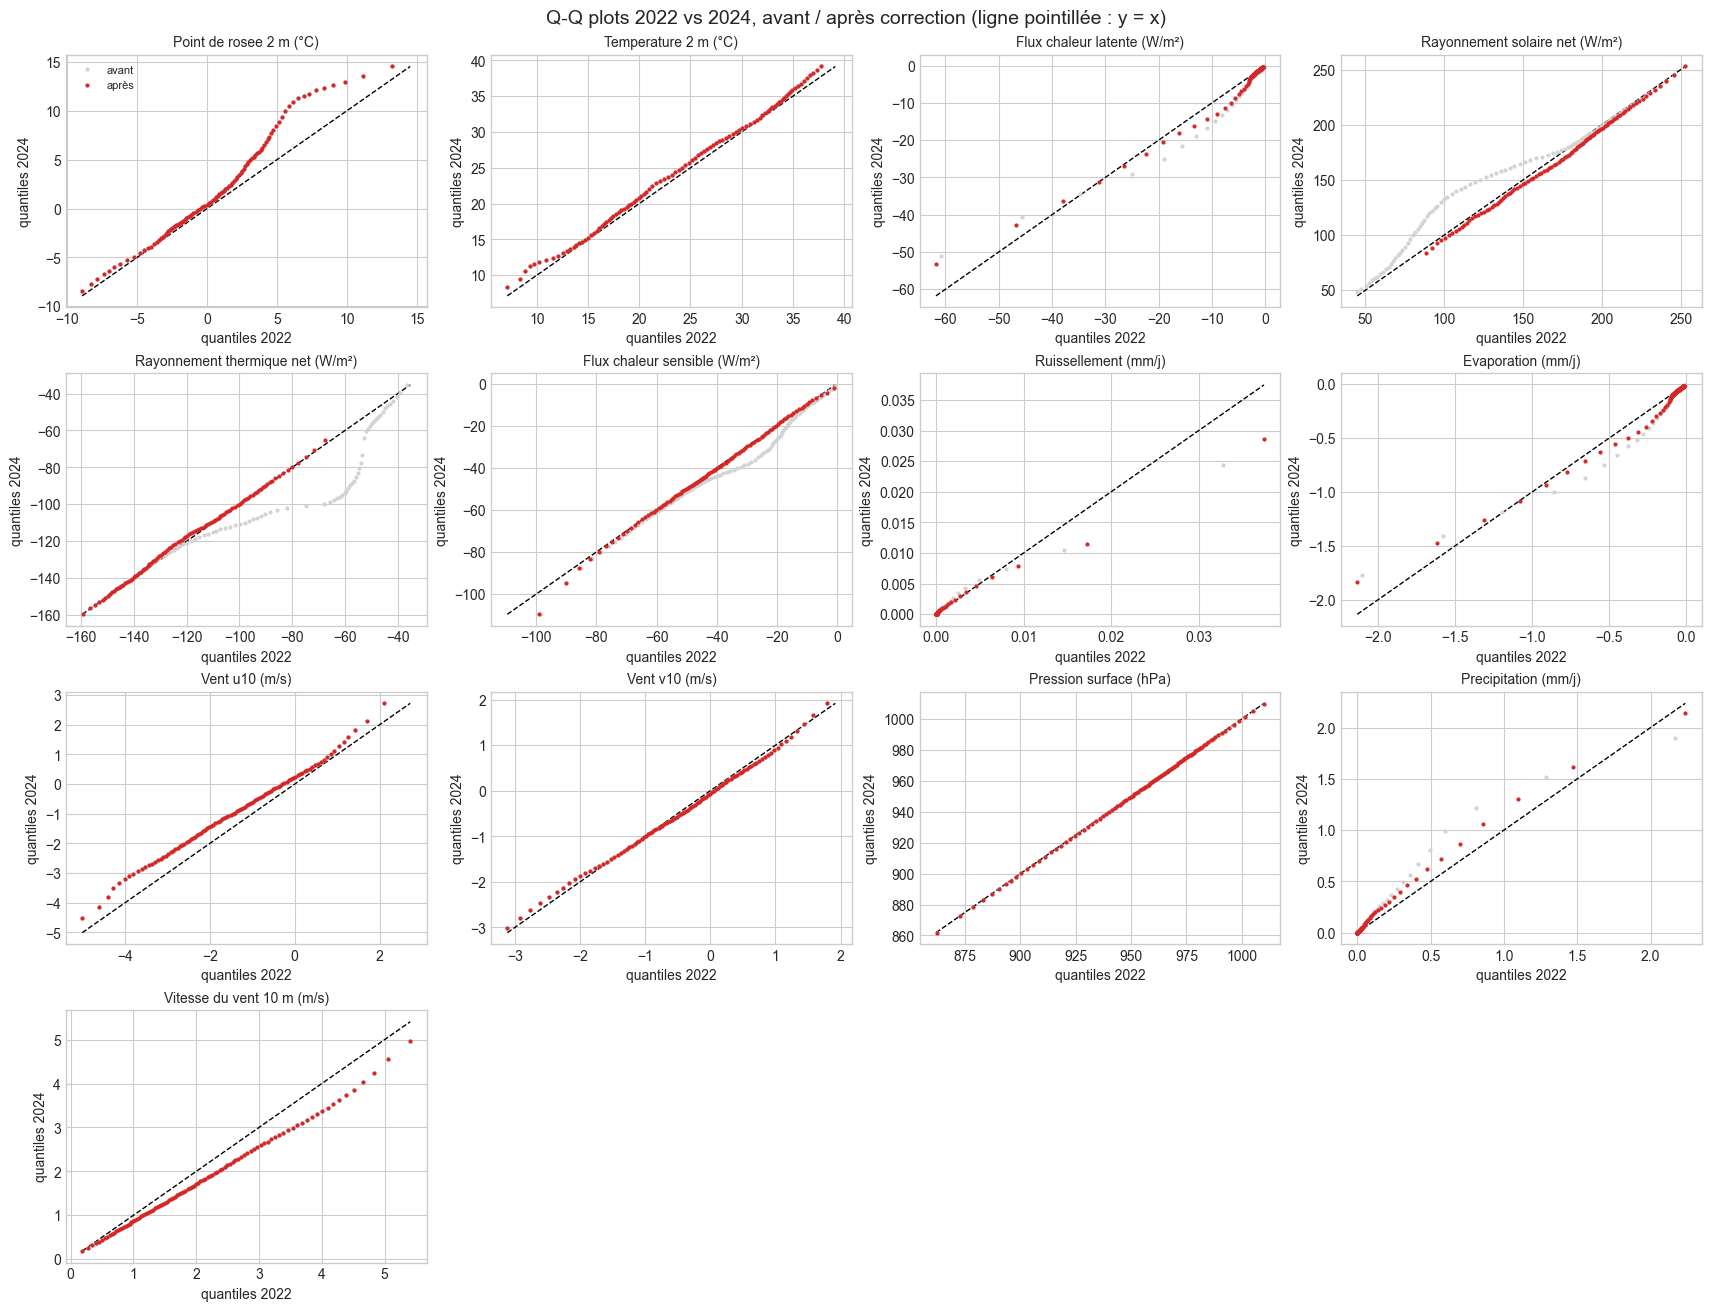

In [8]:
# ---- Q-Q plot 2022 vs 2024 : avant / après correction (99 quantiles, toutes les cellules du domaine) ----
# Si les deux années sont cohérentes, les points suivent la droite y = x.
def year_vals(c, v, y):
    return c[v].sel(valid_time=slice(f"{y}-01-01", f"{y}-12-31")).values[:, vm].ravel()

qs = np.linspace(0.01, 0.99, 99)
fig, axes = plt.subplots(4, 4, figsize=(17, 13), constrained_layout=True)
for ax, v in zip(axes.flat, ALL):
    qa0, qb0 = np.quantile(year_vals(conv, v, 2022), qs), np.quantile(year_vals(conv, v, 2024), qs)     # avant correction
    qa1, qb1 = np.quantile(year_vals(gridc, v, 2022), qs), np.quantile(year_vals(gridc, v, 2024), qs)   # après correction
    lim = [min(qa0.min(), qb0.min(), qa1.min(), qb1.min()), max(qa0.max(), qb0.max(), qa1.max(), qb1.max())]
    ax.plot(lim, lim, "k--", lw=1)
    ax.plot(qa0, qb0, ".", ms=4, color="lightgrey", label="avant")
    ax.plot(qa1, qb1, ".", ms=4, color="tab:red", label="après")
    ax.set_title(LABELS[v], fontsize=10); ax.set_xlabel("quantiles 2022"); ax.set_ylabel("quantiles 2024")
axes.flat[0].legend(fontsize=8)
for ax in axes.flat[len(ALL):]: ax.set_visible(False)
fig.suptitle("Q-Q plots 2022 vs 2024, avant / après correction (ligne pointillée : y = x)", fontsize=14); plt.show()

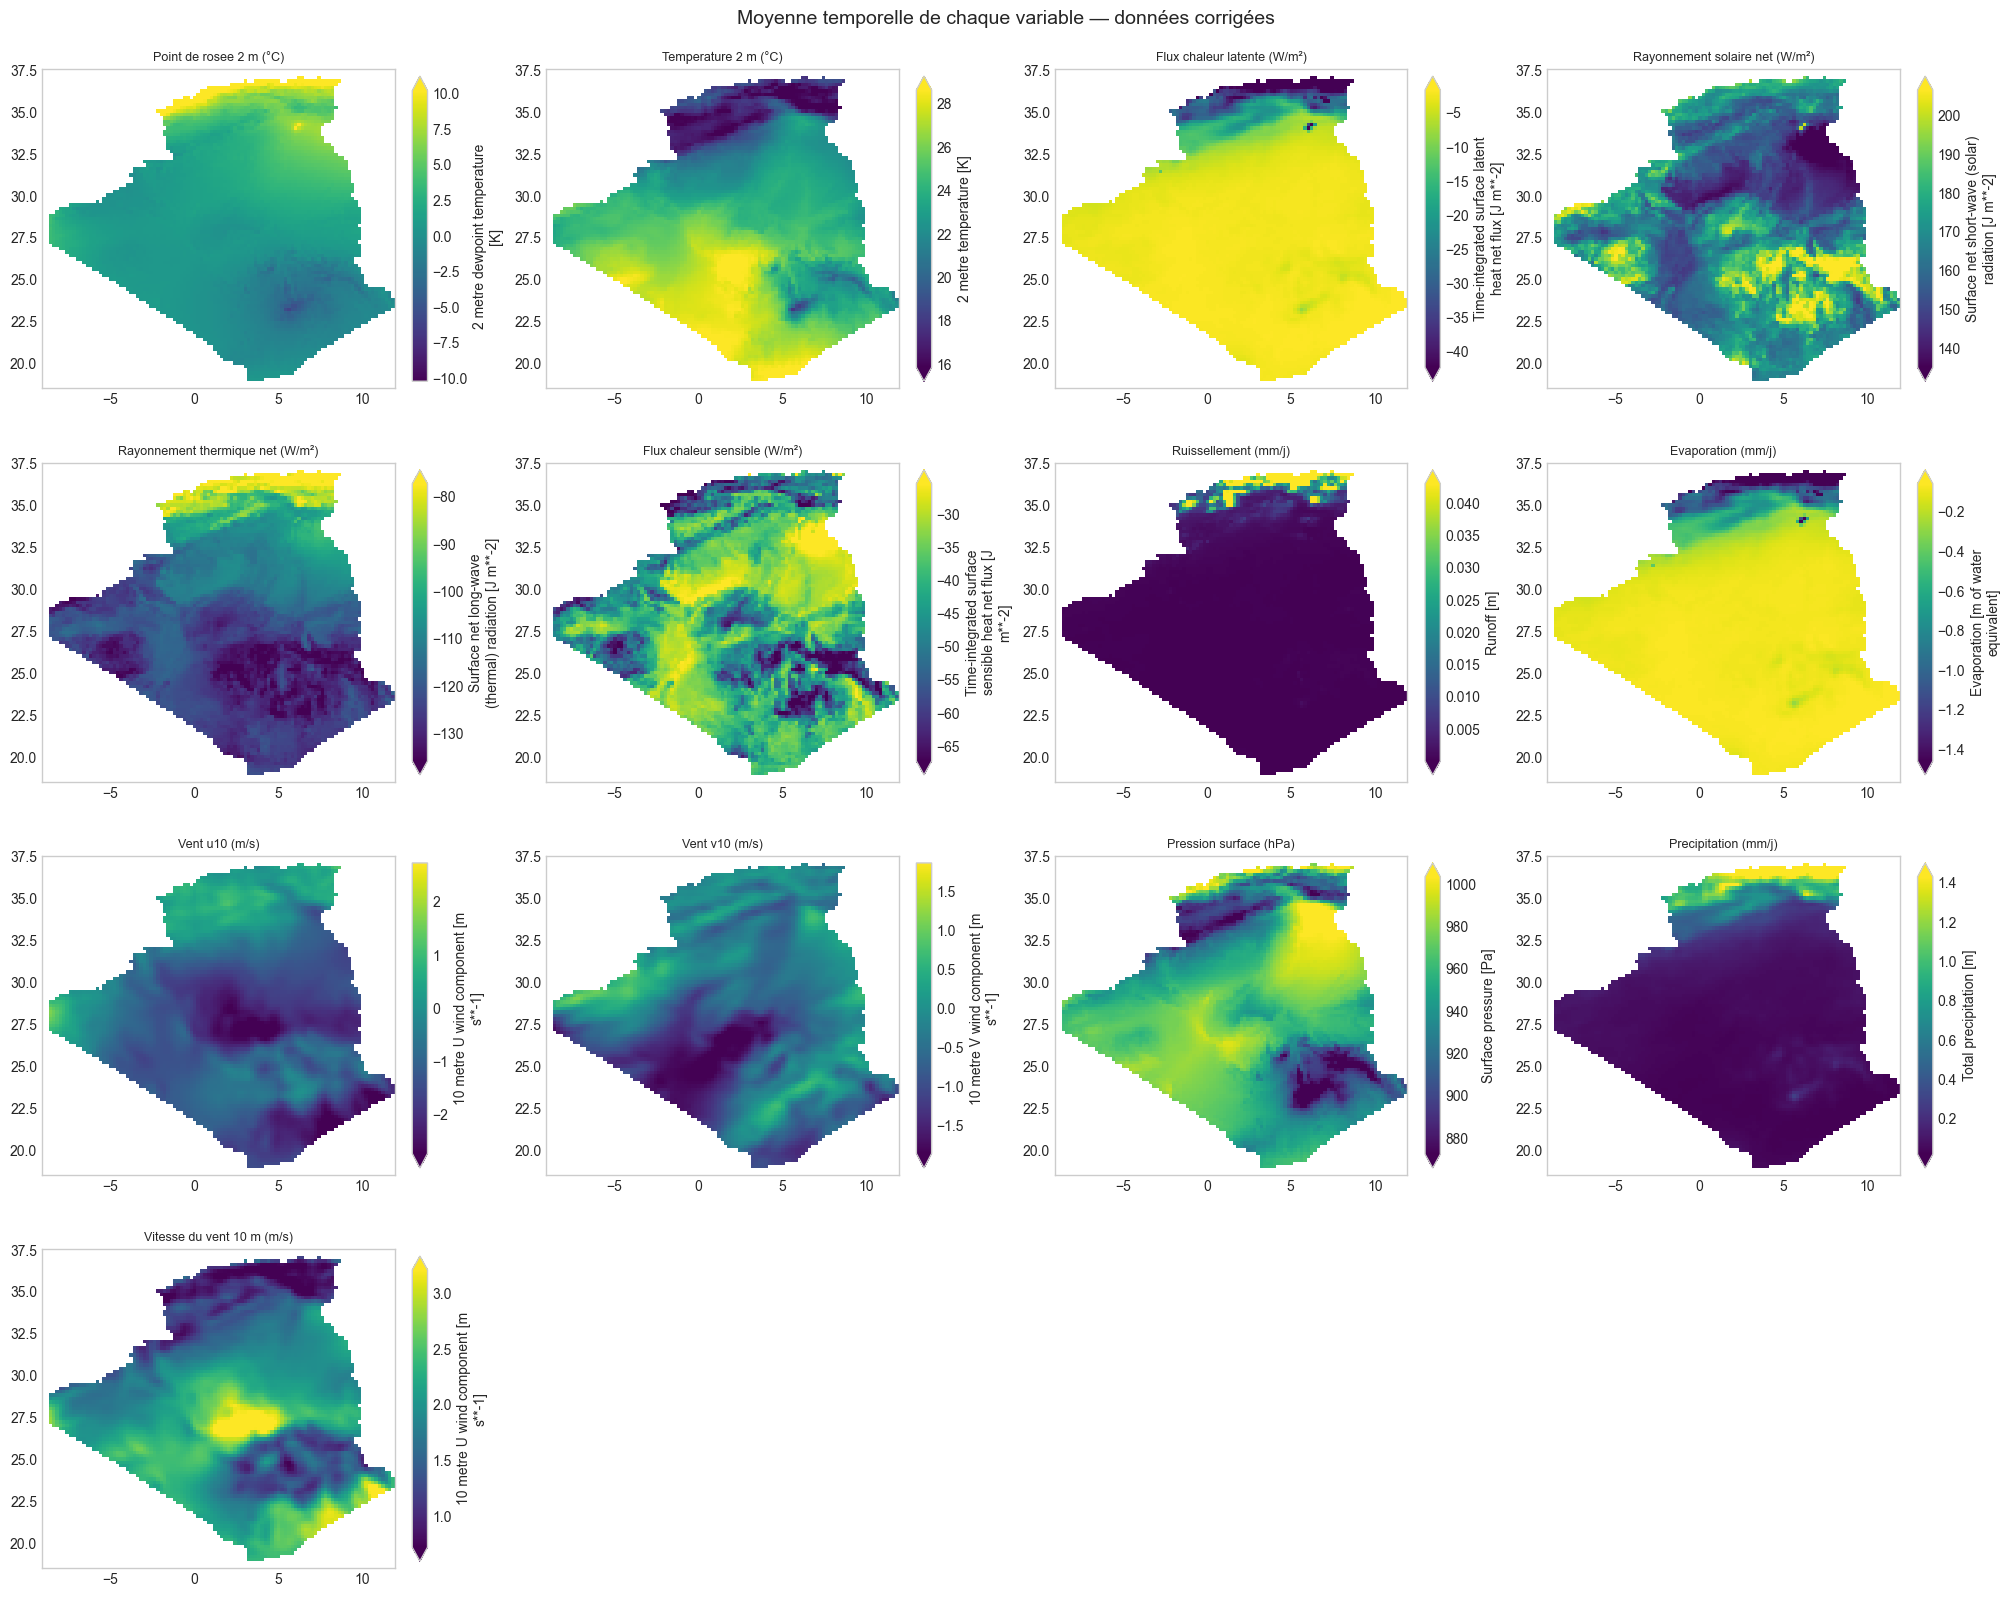

Biais de la moyenne spatio-temporelle dû à l'artefact (EDA §6), en % de la valeur corrigée :


,slhf,ssr,str,sshf,ro,e,tp
écart des cartes de l'EDA (%),-4.6,6.3,-6.0,-5.5,4.1,-4.6,4.6


Contrôle sur les 18 mois corrigés (variables accumulées) :


,slhf,ssr,str,sshf,ro,e,tp
rapport avant,0.347,0.535,0.490,0.489,0.145,0.347,0.264
rapport après,0.695,1.071,0.980,0.977,0.291,0.695,0.528
rapport mois normaux,0.910,1.002,1.003,1.003,0.691,0.910,0.828
|z| médian avant,2.163,22.272,11.995,10.429,1.217,2.163,1.207
|z| médian après,0.961,3.384,0.589,0.627,0.972,0.961,1.045


In [9]:
# ---- Cartes de la moyenne temporelle recalculées sur données corrigées (annoncé en EDA §6) ----
tmean = gridc[ALL].where(valid_cells).mean("valid_time")
fig, axes = plt.subplots(4, 4, figsize=(20, 16), constrained_layout=True)
for ax, v in zip(axes.flat, ALL):
    tmean[v].plot.pcolormesh(ax=ax, x="longitude", y="latitude", cmap="viridis", robust=True, cbar_kwargs={"shrink": .8})
    ax.set_title(LABELS[v], fontsize=9); ax.set_aspect("equal"); ax.set_xlabel(""); ax.set_ylabel("")
for ax in axes.flat[len(ALL):]: ax.set_visible(False)
fig.suptitle("Moyenne temporelle de chaque variable — données corrigées", fontsize=14); plt.show()

bias = pd.Series({v: 100 * (float(gridc[v].where(valid_cells).mean()) - float(conv[v].where(valid_cells).mean())) / abs(float(gridc[v].where(valid_cells).mean()))
                  for v in ACCUMULATED}, name="écart des cartes de l'EDA (%)").round(1)
print("Biais de la moyenne spatio-temporelle dû à l'artefact (EDA §6), en % de la valeur corrigée :")
display(bias.to_frame().T)

check = pd.DataFrame({"rapport avant": ratio_before[is_aff][ACCUMULATED].median(),
                      "rapport après": ratio_after[is_aff][ACCUMULATED].median(),
                      "rapport mois normaux": ratio_before[~is_aff][ACCUMULATED].median(),
                      "|z| médian avant": z_before[is_aff][ACCUMULATED].abs().median(),
                      "|z| médian après": z_after[is_aff][ACCUMULATED].abs().median()}).round(3)
print("Contrôle sur les 18 mois corrigés (variables accumulées) :"); display(check.T)

**Effet.** Après correction, les variables accumulées retrouvent sur les 18 mois des anomalies dans la plage normale (|z| de l'ordre de ceux des autres mois). Sur le Q-Q plot 2022 vs 2024, les points « après » doivent se rapprocher de la diagonale y = x par rapport aux points « avant », pour les variables accumulées seulement. Les variables instantanées n'ont pas été modifiées (leurs courbes « avant » et « après » sont superposées).

**Ce qu'on ne corrige pas.** Après correction, 2022 et 2024 ne sont pas identiques, et ils n'ont pas à l'être : il reste de vrais écarts climatiques (visibles aussi sur `t2m` et `d2m`, non touchées par l'artefact). On corrige l'artefact documenté, pas la variabilité du climat. Pour `ro`, `tp` et `slhf`/`e`, le rapport « mois normaux » est lui-même éloigné de 1 : la moyenne régionale d'une variable intermittente est dominée par quelques mois humides, d'où l'intérêt de lire aussi le |z|.

**Limite.** Un facteur constant reconstitue l'ordre de grandeur et la variabilité, pas les valeurs exactes. La solution idéale reste de re-télécharger les 18 mois via le contournement de l'ECMWF. Les lignes dont le mois M appartient à la période corrigée sont repérées par la colonne `anomaly_corrected` (exportée) pour l'analyse d'erreurs.

## 3. Cohérence physique et décision sur les outliers

**Constat EDA §2.** `slhf`, `e`, `ro` et `tp` ont 15-16 % d'outliers selon l'IQR et 0,7-2,8 % selon le Z-score ; les autres variables ≈ 1 % ou moins.

**Pourquoi on ne supprime pas ces valeurs.**
1. Les causes d'outliers du cours 03 sont les erreurs de saisie, les erreurs de capteur et les **cas extrêmes naturels**. ERA5-Land est une réanalyse (modèle physique contraint par des observations) : pas de saisie ni de capteur défaillant au niveau de la cellule. Le seul défaut systématique du produit (§2) est déjà corrigé.
2. Ces « outliers » viennent de la **forme** de la distribution, pas d'erreurs : la pluie, le ruissellement et l'évaporation sont quasi nuls la plupart du temps au Sahara et forts quelques mois sur le Tell. L'IQR et le Z-score supposent une distribution unimodale à peu près symétrique : sur une distribution à queue lourde, ils signalent mécaniquement la queue.
3. Supprimer ces lignes retirerait les mois pluvieux du nord, donc une région climatique entière (et casserait la grille cellule × mois nécessaire à la cible M+1). Les tronquer (*capping*) écraserait l'information sur les événements forts.

**Méthode (cours 04 « Handling outliers »).** (a) **Inspection combinée machine + expert** : des règles physiques ; on ne retire que ce qui est physiquement impossible. (b) Les queues lourdes sont ensuite traitées par **transformation** (§7).

In [10]:
X = gridc[ALL].where(valid_cells)
rules = {
    "tp < 0 (précipitation négative)":            (X["tp"] < 0),
    "ro < 0 (ruissellement négatif)":             (X["ro"] < 0),
    "ssr < 0 (rayonnement solaire net négatif)":  (X["ssr"] < 0),
    "d2m > t2m + 0.05 (rosée > température)":     (X["d2m"] > X["t2m"] + 0.05),
    "sp hors [500, 1100] hPa":                    ((X["sp"] < 500) | (X["sp"] > 1100)),
    "|u10| ou |v10| > 40 m/s":                    ((abs(X["u10"]) > 40) | (abs(X["v10"]) > 40)),
}
phys = pd.Series({k: int(m.sum()) for k, m in rules.items()}, name="violations")
display(phys.to_frame())

# Seule correction prévue : petites valeurs négatives numériques de tp / ro (arrondi de la réanalyse) -> 0
for v in ["tp", "ro"]:
    n_neg = int((gridc[v] < 0).sum())
    gridc[v] = gridc[v].clip(min=0)
    if n_neg: print(f"{v} : {n_neg} valeurs négatives mises à 0")
n_viol_other = int(phys.iloc[2:].sum())
print("Violations physiques restantes (hors tp/ro) :", n_viol_other)
log_step("3. Cohérence physique", "aucune suppression ; tp/ro bornés à 0" if n_viol_other == 0 else f"{n_viol_other} violation(s) à examiner",
         violations=phys.to_dict())

,violations
tp < 0 (précipitation négative),0
ro < 0 (ruissellement négatif),0
ssr < 0 (rayonnement solaire net négatif),0
d2m > t2m + 0.05 (rosée > température),0
"sp hors [500, 1100] hPa",0
|u10| ou |v10| > 40 m/s,0


Violations physiques restantes (hors tp/ro) : 0
[LOG] 3. Cohérence physique → aucune suppression ; tp/ro bornés à 0


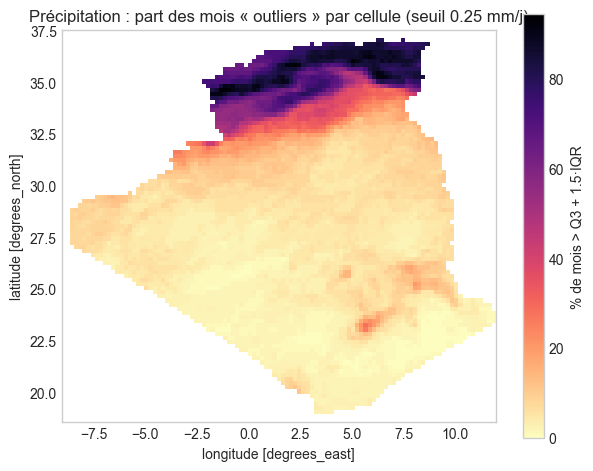

Part d'outliers IQR de tp sur le Train : 15.1 % des échantillons — structure spatiale continue (nord du pays), pas des points isolés : c'est la climatologie, pas une erreur.


In [11]:
# Les « outliers » de tp sont-ils des erreurs isolées ou une réalité climatique ? -> localisation spatiale
# (descriptif uniquement, sur les mois du Train ; aucun paramètre n'est ajusté ici)
tr_tp = gridc["tp"].sel(valid_time=slice(TIMES.min(), LAST_TRAIN_FEATURE))
vals = tr_tp.values[:, vm]
q1_, q3_ = np.nanpercentile(vals, [25, 75]); fence = q3_ + 1.5 * (q3_ - q1_)
share = (tr_tp > fence).mean("valid_time").where(valid_cells) * 100

fig, ax = plt.subplots(figsize=(7, 5.5))
share.plot.pcolormesh(ax=ax, x="longitude", y="latitude", cmap="magma_r", cbar_kwargs={"label": "% de mois > Q3 + 1.5·IQR"})
ax.set_aspect("equal"); ax.set_title(f"Précipitation : part des mois « outliers » par cellule (seuil {fence:.2f} mm/j)"); plt.show()
print(f"Part d'outliers IQR de tp sur le Train : {100 * float((vals > fence).mean()):.1f} % des échantillons — "
      "structure spatiale continue (nord du pays), pas des points isolés : c'est la climatologie, pas une erreur.")

## 4. Tableau d'échantillons et intégration de la cible (température au mois M+1)

**Unité statistique :** une ligne = une **cellule** au mois **M** (même structure que l'EDA : `cell`, `lat`, `lon`, `time`, `year`, `month`). Le sujet n'agrège pas spatialement : la grille a déjà été réduite d'un facteur 4 dans le notebook 01.

**Construction de la cible.** Pour chaque cellule, `t2m_next(M) = t2m(M+1)` de **la même cellule**. Le décalage se fait sur le tableau (temps × cellules) **avant** la mise à plat : une cellule ne peut jamais recevoir la température d'une autre, et le mois suivant est toujours le mois calendaire suivant (axe vérifié continu au §1). Le dernier mois (septembre 2026) n'a pas de mois suivant : ses lignes sont retirées (ce n'est pas une imputation, la cible n'existe pas).

**t2m(M) n'est pas une feature :** le sujet fixe la liste des variables d'entrée, et `t2m` n'y figure pas ; elle ne sert qu'à construire la cible. La **vitesse du vent** `wind10_speed` = √(u10² + v10²) est conservée comme feature dérivée (déjà introduite par l'EDA ; interrupteur `USE_WIND_SPEED`) : elle passera, comme les autres, le contrôle de redondance du §6.

In [12]:
grid = {v: gridc[v].values[:, vm] for v in ALL}                     # chaque tableau : (T, N) — données corrigées
target = np.vstack([grid["t2m"][1:], np.full((1, N), np.nan)])      # t2m(M+1) de la MÊME cellule

df = pd.DataFrame({v: grid[v].reshape(-1) for v in CAND})
df.insert(0, "time", np.repeat(TIMES.values, N))
df.insert(1, "cell", np.tile(np.arange(N), T))
df.insert(2, "lat", np.tile(gridc.latitude.values[ilat], T))
df.insert(3, "lon", np.tile(gridc.longitude.values[ilon], T))
df["month"] = df["time"].dt.month
df["year"] = df["time"].dt.year
df["t2m_next"] = target.reshape(-1)
df["target_time"] = df["time"] + pd.offsets.MonthBegin(1)
df["anomaly_corrected"] = df["time"].isin(AFFECTED).astype(int)    # 1 = mois M corrigé (§2) ; pour l'analyse d'erreurs, jamais une feature

n0 = len(df)
df = df.dropna(subset=["t2m_next"]).reset_index(drop=True)
print(f"{n0:,} lignes → {len(df):,} après retrait du dernier mois ({n0 - len(df):,} lignes = {N:,} cellules × 1 mois)")

# Vérification indépendante sur 2000 lignes tirées au hasard : cible = t2m de la même cellule, mois suivant
chk = df.sample(2000, random_state=1)
ref_vals = gridc["t2m"].sel(latitude=xr.DataArray(chk["lat"].values), longitude=xr.DataArray(chk["lon"].values),
                            valid_time=xr.DataArray(chk["target_time"].values)).values
assert np.allclose(ref_vals, chk["t2m_next"].values), "Erreur de construction de la cible M+1"
assert df[CAND + ["t2m_next"]].notna().all().all() and not df.duplicated(["cell", "time"]).any()
print("Cible M+1 vérifiée (même cellule, mois suivant) ✔ — aucune valeur manquante ✔ — aucun doublon (cellule, mois) ✔")
display(df[["cell", "lat", "lon", "time", "target_time", "t2m_next"]].head(3))
log_step("4. Cible", "t2m(M+1) de la même cellule ; dernier mois retiré", lignes_retirees=int(n0 - len(df)))

764,784 lignes → 759,360 après retrait du dernier mois (5,424 lignes = 5,424 cellules × 1 mois)
Cible M+1 vérifiée (même cellule, mois suivant) ✔ — aucune valeur manquante ✔ — aucun doublon (cellule, mois) ✔


,cell,lat,lon,time,target_time,t2m_next
0,0,37.05,6.25,2015-01-01,2015-02-01,8.681549
1,1,37.05,6.45,2015-01-01,2015-02-01,8.487213
2,2,37.05,7.45,2015-01-01,2015-02-01,9.768463


[LOG] 4. Cible → t2m(M+1) de la même cellule ; dernier mois retiré


## 5. Séparation Train / Test chronologique

**Pourquoi chronologique.** Le sujet l'impose, et c'est indispensable pour une prévision. Un découpage aléatoire placerait dans le Train des mois postérieurs à des mois du Test, et des cellules voisines du même mois (très corrélées spatialement) dans les deux ensembles : scores artificiellement élevés = **fuite de données**.

**Frontière définie sur le mois de la cible.**
- **Train :** mois cible de février 2015 à **décembre 2023** (features de janvier 2015 à novembre 2023) ;
- **Test :** mois cible de **janvier 2024** à septembre 2026 (features de décembre 2023 à août 2026).

Conséquences : (1) aucune température utilisée comme cible dans le Train n'est postérieure au début du Test, et aucune ligne n'est perdue à la frontière ; (2) la coupure tombe sur une fin d'année : le Train contient **9 années complètes** de mois cibles (chaque mois calendaire y apparaît 9 fois, saisons équilibrées) ; (3) ≈ 76 % / 24 %, proche du ratio usuel 80/20, avec un Test de plus de deux cycles saisonniers.

**Validation pour la suite.** Les hyperparamètres se règlent par découpage chronologique **du Train** (`TimeSeriesSplit`), jamais avec le Test.

,lignes,% lignes,mois features,mois cibles,nb mois
Train,580368,76.4,2015-01 → 2023-11,2015-02 → 2023-12,107
Test,178992,23.6,2023-12 → 2026-08,2024-01 → 2026-09,33


Aucun chevauchement temporel entre Train et Test ✔ — toutes les cellules sont dans les deux ensembles ✔


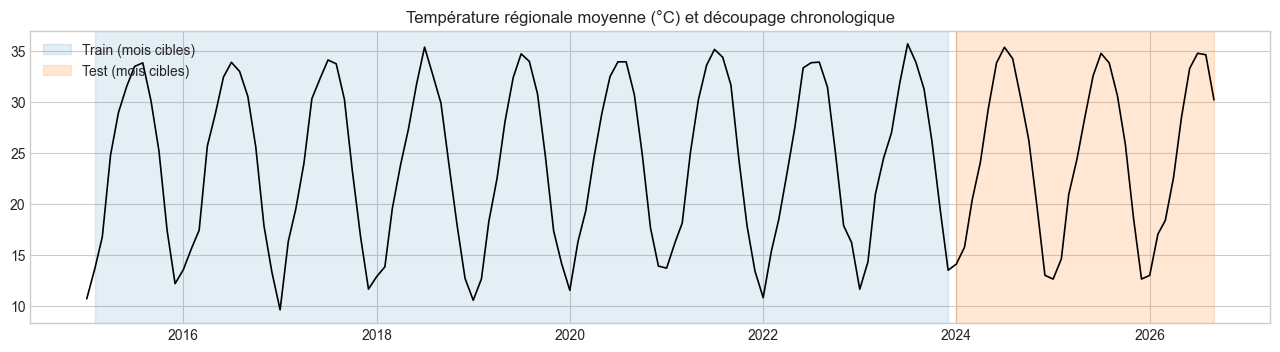

[LOG] 5. Split → chronologique sur le mois cible (< 2024-01 → Train)


In [13]:
is_test = df["target_time"] >= SPLIT_TARGET
train, test = df[~is_test].copy(), df[is_test].copy()

split_info = pd.DataFrame({
    "lignes": [len(train), len(test)],
    "% lignes": [100 * len(train) / len(df), 100 * len(test) / len(df)],
    "mois features": [f"{train.time.min():%Y-%m} → {train.time.max():%Y-%m}", f"{test.time.min():%Y-%m} → {test.time.max():%Y-%m}"],
    "mois cibles": [f"{train.target_time.min():%Y-%m} → {train.target_time.max():%Y-%m}", f"{test.target_time.min():%Y-%m} → {test.target_time.max():%Y-%m}"],
    "nb mois": [train.time.nunique(), test.time.nunique()]}, index=["Train", "Test"]).round(1)
display(split_info)

assert train["target_time"].max() < test["target_time"].min() and train["time"].max() < test["time"].min()
assert set(train["cell"]) == set(test["cell"]) and len(train) + len(test) == len(df)
assert train["time"].max() == LAST_TRAIN_FEATURE
print("Aucun chevauchement temporel entre Train et Test ✔ — toutes les cellules sont dans les deux ensembles ✔")

# Visualisation : série régionale de t2m avec les deux périodes (même figure que l'EDA §3)
fig, ax = plt.subplots(figsize=(16, 3.8))
ax.plot(reg_after.index, reg_after["t2m"], lw=1.2, color="k")
ax.axvspan(train["target_time"].min(), train["target_time"].max(), color="tab:blue", alpha=.12, label="Train (mois cibles)")
ax.axvspan(test["target_time"].min(), test["target_time"].max(), color="tab:orange", alpha=.18, label="Test (mois cibles)")
ax.set_title("Température régionale moyenne (°C) et découpage chronologique"); ax.legend(loc="upper left"); plt.show()
log_step("5. Split", "chronologique sur le mois cible (< 2024-01 → Train)", n_train=len(train), n_test=len(test))

## 6. Sélection des features : redondance et faible variabilité (décidée sur le Train)

**Pourquoi recalculer ici.** Les corrélations et variances de l'EDA ont été calculées (i) **avant** la correction de 2022-2024 et (ii) **sur toute la période**, Test compris. L'artefact divisait **simultanément** par 2 toutes les variables accumulées, ce qui gonfle mécaniquement leurs corrélations mutuelles. Les décisions reposent donc sur les données corrigées du **Train**.

### 6.1 Formule de corrélation : Spearman (conclusion de l'EDA §5.1)

L'EDA a appliqué Shapiro-Wilk à chaque variable : **aucune n'est normale** (avec ≈ 580 000 lignes tout test rejette dès que l'écart est minime, et l'asymétrie / les outliers de l'EDA §2 le confirment). On retient donc **Spearman** (calculé sur les rangs : relations monotones non linéaires, robuste aux queues lourdes et aux outliers, cours 03).

Le test de normalité et la comparaison Pearson / Spearman ne sont **pas refaits** ; on recalcule seulement Spearman sur le **Train corrigé**, qui est la matrice sur laquelle reposent les décisions.


In [14]:
CORR_METHOD = "spearman"      # conclusion de l'EDA §5.1 : aucune variable normale -> Spearman (test non refait ici)

def pair_table(m):
    i, j = np.triu_indices(len(m), 1)
    return pd.DataFrame({"var 1": m.index[i], "var 2": m.columns[j], "r": m.values[i, j]})

corr_s = train[CAND].rank().corr()                  # Spearman = Pearson sur les rangs ; Train, données corrigées
pairs = pair_table(corr_s)
HIGH = pairs[pairs["r"].abs() > CORR_THRESHOLD].sort_values("r", key=abs, ascending=False).reset_index(drop=True)
print(f"Paires |r| > {CORR_THRESHOLD} (Spearman, Train corrigé — seuil du cours : candidates à la redondance) :"); display(HIGH.round(3))
log_step("6.1 Formule de corrélation", "Spearman (conclusion EDA §5.1 : aucune variable normale)")

Paires |r| > 0.9 (Spearman, Train corrigé — seuil du cours : candidates à la redondance) :


,var 1,var 2,r
0,slhf,e,1.000
1,ro,tp,0.980
2,ssr,sshf,-0.948


[LOG] 6.1 Formule de corrélation → Spearman (conclusion EDA §5.1 : aucune variable normale)


### 6.2 Redondance : ne pas supprimer aveuglément

Le critère du cours 04 (« What features to eliminate ») est : corrélation > 0,9, variance < 0,01, variable non pertinente. On ne l'applique pas mécaniquement : une corrélation élevée peut venir uniquement du **cycle saisonnier commun** (deux variables physiquement distinctes qui suivent toutes deux les saisons). On calcule donc aussi la corrélation des **anomalies** : la valeur moins la climatologie de la cellule pour ce mois calendaire (estimée sur le Train). Deux variables vraiment redondantes restent corrélées une fois la saison retirée ; deux variables distinctes ne le restent pas.

In [15]:
clim_tr = train.groupby(["cell", "month"])[CAND].transform("mean")           # climatologie Train (cellule × mois calendaire)
rho_anom = (train[CAND] - clim_tr).rank().corr()
rho_t = train[CAND].corrwith(train["t2m_next"], method="spearman")           # lien de chaque variable avec la cible (filtre, cours 05)

pairs["Spearman anomalies"] = [rho_anom.loc[a, b] for a, b in zip(pairs["var 1"], pairs["var 2"])]
pairs["|ρ cible| var 1"] = [abs(rho_t[a]) for a in pairs["var 1"]]
pairs["|ρ cible| var 2"] = [abs(rho_t[b]) for b in pairs["var 2"]]
top = pairs[pairs["r"].abs() > 0.8].sort_values("r", key=abs, ascending=False).reset_index(drop=True)
print("Paires avec |r| > 0.8 sur le Train corrigé (r : formule retenue ; anomalies = saison retirée) :"); display(top.round(3))

Paires avec |r| > 0.8 sur le Train corrigé (r : formule retenue ; anomalies = saison retirée) :


,var 1,var 2,r,Spearman anomalies,|ρ cible| var 1,|ρ cible| var 2
0,slhf,e,1.000,1.000,0.157,0.157
1,ro,tp,0.980,0.910,0.209,0.203
2,ssr,sshf,-0.948,-0.185,0.811,0.719


### 6.3 Faible variabilité (EDA §1.3, non refait)

Le tableau de variance (unités d'analyse, Min-Max, % de variance temporelle) est celui de l'EDA §1.3 ; il n'est pas recalculé. Les chiffres utiles aux décisions (`ro`, `sp`) sont calculés en §6.4, et la variance Min-Max est réévaluée **après** la transformation en §7 (c'est là qu'elle change).


### 6.4 Décisions, variable par variable

**`slhf` et `e` : une seule grandeur physique.** Le flux de chaleur latente **est** l'évaporation exprimée en énergie : slhf = ρ_w · L_v · e, avec L_v ≈ 2,5·10⁶ J/kg, soit slhf [W/m²] ≈ 28,9 × e [mm/j]. Les deux colonnes portent exactement la même information ; garder les deux **double le poids** de l'évaporation dans les distances du KNN et du SVM. → **suppression de `e`** (on garde `slhf`, dans la même unité que les autres termes du bilan d'énergie de surface). Vérification numérique du rapport constant ci-dessous.

**`ro` : quasi constante et redondante avec `tp`.** Trois arguments qui se renforcent : (i) *faible variabilité* : médiane et Q3 = 0, une très grande part des échantillons ≈ 0 (seul cas < 0,01 en unités d'analyse dans l'EDA) ; (ii) *redondance* : Spearman `ro`–`tp` ≈ 0,98, le ruissellement n'apparaît que là où il pleut ; (iii) *pertinence* : pas de lien physique direct avec la température du mois suivant, son effet indirect (humidité du sol) est déjà porté par `tp` et `slhf`. *Remarque honnête :* le Pearson `ro`–`tp` est bien plus faible que le Spearman (les deux sont nulles ensemble dans le désert : beaucoup d'ex æquo) ; la décision repose donc sur la **combinaison** des trois arguments, pas sur la corrélation seule. → **suppression de `ro`**.

**`ssr` et `sshf` : corrélées par la saison, physiquement distinctes.** ρ ≈ −0,95, juste au-dessus du seuil. `ssr` est le rayonnement solaire **absorbé** ; `sshf` est le flux de chaleur **sensible**, qui dépend de l'écart de température sol-air et de l'humidité du sol (partage chaleur sensible / latente). Leur corrélation brute vient surtout du cycle saisonnier commun : la règle appliquée ci-dessous est de **conserver les deux tant que |ρ des anomalies| < 0,9**. Le cours 04 précise d'ailleurs que la redondance pénalise surtout les modèles de type *régression* ; KNN, SVM, Random Forest et ensembles y sont peu sensibles. *(Si l'enseignante exige le retrait strict de toute paire > 0,9, mettre `MANUAL_DROP = ["sshf"]` dans la cellule de configuration : `sshf` est alors retirée, `ssr` étant plus liée à la cible.)*

**`sp` : faible variabilité *temporelle*, forte variabilité spatiale → conservée.** `sp` n'a qu'≈ 1 % de variance temporelle, mais une variance totale élevée : la pression de surface est presque entièrement déterminée par l'**altitude** de la cellule. C'est un proxy d'altitude, information spatiale déterminante pour la température (≈ −6,5 °C/km). La faible variabilité signalée concerne le temps, pas l'espace.

**Autres paires > 0,9** (si une autre apparaissait) : retrait de la variable la moins liée à la cible (méthode filtre, cours 05).

slhf / e : rapport médian = 28.94 W/m² par mm/j (théorie ≈ 28.9) ; écart interquartile = 0.000 ; Pearson = 1.0000
ro : 95.8 % des échantillons < 0.01 mm/j ; IQR = 0.0004 ; Spearman(ro, tp) = 0.980 ; Pearson(ro, tp) = 0.495
ssr / sshf : Spearman brut = -0.948 ; Spearman des anomalies = -0.185  |  |ρ cible| : ssr 0.811, sshf 0.719
  ↳ corrélation due au cycle saisonnier commun : ssr et sshf conservées
sp : 1.1 % de variance temporelle ; écart-type total = 33.5 hPa → conservée (proxy d'altitude)

Features supprimées :
  - e : même grandeur que slhf (Pearson 1.0000, rapport constant)
  - ro : quasi constante (96 % < 0.01 mm/j), information portée par tp (Spearman 0.98)
Features conservées : ['d2m', 'slhf', 'ssr', 'str', 'sshf', 'u10', 'v10', 'sp', 'tp', 'wind10_speed']
[LOG] 6. Sélection → retirées : ['e', 'ro']
Paires > 0.9 restantes (volontairement conservées, corrélées par la saison) : [('ssr', 'sshf', -0.948)]


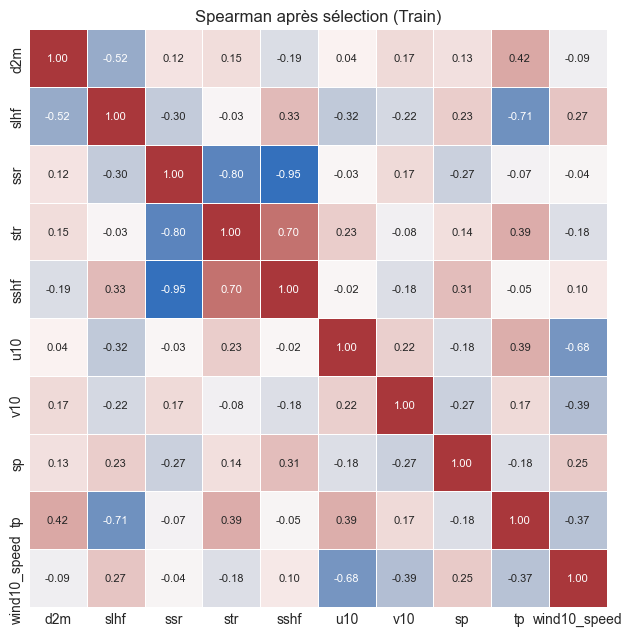

In [16]:
DROP, REASONS = [], {}

# slhf / e : même grandeur physique
ratio_le = (train["slhf"] / train["e"]).replace([np.inf, -np.inf], np.nan).dropna()
r_le = float(train[["slhf", "e"]].corr().iloc[0, 1])
print(f"slhf / e : rapport médian = {ratio_le.median():.2f} W/m² par mm/j (théorie ≈ 28.9) ; écart interquartile = "
      f"{ratio_le.quantile(.75) - ratio_le.quantile(.25):.3f} ; Pearson = {r_le:.4f}")
if r_le > 0.99:
    DROP.append("e"); REASONS["e"] = f"même grandeur que slhf (Pearson {r_le:.4f}, rapport constant)"

# ro : quasi constante + redondante avec tp
share0 = float((train["ro"] < 0.01).mean()); rho_ro = float(corr_s.loc["ro", "tp"])
print(f"ro : {100 * share0:.1f} % des échantillons < 0.01 mm/j ; IQR = {train['ro'].quantile(.75) - train['ro'].quantile(.25):.4f} ; "
      f"Spearman(ro, tp) = {rho_ro:.3f} ; Pearson(ro, tp) = {train[['ro', 'tp']].corr().iloc[0, 1]:.3f}")
if share0 > 0.5:
    DROP.append("ro"); REASONS["ro"] = f"quasi constante ({100 * share0:.0f} % < 0.01 mm/j), information portée par tp (Spearman {rho_ro:.2f})"

# ssr / sshf : corrélation brute vs anomalies
r_raw, r_an = float(corr_s.loc["ssr", "sshf"]), float(rho_anom.loc["ssr", "sshf"])
print(f"ssr / sshf : Spearman brut = {r_raw:.3f} ; Spearman des anomalies = {r_an:.3f}  |  |ρ cible| : ssr {abs(rho_t['ssr']):.3f}, sshf {abs(rho_t['sshf']):.3f}")
if abs(r_an) > CORR_THRESHOLD:
    DROP.append("sshf"); REASONS["sshf"] = f"redondante avec ssr même hors saison (ρ anomalies {r_an:.2f})"
else:
    print("  ↳ corrélation due au cycle saisonnier commun : ssr et sshf conservées")

# sp : faible variance temporelle mais forte variance spatiale (proxy d'altitude) -> conservée
sp_temp = 100 * float(train.groupby("cell")["sp"].var(ddof=0).mean()) / float(train["sp"].var(ddof=0))
print(f"sp : {sp_temp:.1f} % de variance temporelle ; écart-type total = {train['sp'].std():.1f} hPa → conservée (proxy d'altitude)")

# filet de sécurité : toute autre paire > 0.9 non couverte -> retirer la variable la moins liée à la cible
covered = [{"slhf", "e"}, {"ro", "tp"}, {"ssr", "sshf"}]
for _, p in HIGH.iterrows():
    a, b = p["var 1"], p["var 2"]
    if {a, b} in covered or a in DROP or b in DROP:
        continue
    drop, keep = (a, b) if abs(rho_t[a]) < abs(rho_t[b]) else (b, a)
    DROP.append(drop); REASONS[drop] = f"redondante avec {keep} (|ρ| = {abs(p['r']):.2f}) et moins liée à la cible"
for v in MANUAL_DROP:
    if v not in DROP:
        DROP.append(v); REASONS[v] = "retrait manuel (MANUAL_DROP)"

FEATURES_KEPT = [v for v in CAND if v not in DROP]
print("\nFeatures supprimées :"); [print(f"  - {k} : {r}") for k, r in REASONS.items()]
print("Features conservées :", FEATURES_KEPT)
log_step("6. Sélection", f"retirées : {DROP}", raisons=REASONS, sp="conservée (proxy altitude)")

rem = pair_table(corr_s.loc[FEATURES_KEPT, FEATURES_KEPT]); rem = rem[rem["r"].abs() > CORR_THRESHOLD]
print("Paires > 0.9 restantes (volontairement conservées, corrélées par la saison) :", [(a, b, round(r, 3)) for a, b, r in rem.values] or "aucune")

fig, ax = plt.subplots(figsize=(9, 7.5))
sns.heatmap(corr_s.loc[FEATURES_KEPT, FEATURES_KEPT], annot=True, fmt=".2f", cmap="vlag", center=0, vmin=-1, vmax=1, square=True,
            linewidths=.5, cbar=False, ax=ax, annot_kws={"size": 8}); ax.set_title("Spearman après sélection (Train)"); plt.show()

## 7. Transformation des distributions très asymétriques

**Problème (EDA §2).** `slhf` (skew −4,2) et `tp` (5,8) ont des queues très lourdes, avec la plupart des valeurs tassées près de zéro. Pour un modèle à **distance** (KNN, SVM-RBF), quelques valeurs extrêmes occupent presque toute l'étendue de la variable après mise à l'échelle, et 90 % des échantillons ne diffèrent plus que de quelques centièmes. C'est exactement la « faible variance Min-Max » relevée dans l'EDA : elle ne vient pas d'une variable pauvre en information mais d'une échelle dominée par la queue.

**Méthode (cours 04 « Handling outliers : transforming the data », cours 05 « Mathematical functions ») : logarithme signé** x′ = sign(x)·ln(1 + |x|).
- défini en 0 (`tp` nul) et pour des valeurs négatives (`slhf` est négatif par convention ECMWF), contrairement à log(x) ;
- **monotone** : l'ordre des valeurs est conservé ; **sans paramètre** : rien n'est appris, aucune fuite ;
- il comprime la queue **sans supprimer** les extrêmes, ce qui complète la décision du §3.

**Règle de sélection.** On transforme une feature si (i) son asymétrie **sur le Train** dépasse 1 en valeur absolue (seuil usuel de « forte asymétrie », Bulmer 1979 ; il n'est pas donné dans le cours) **et** (ii) le log signé **réduit effectivement** cette asymétrie. La condition (ii) écarte les variables dont l'asymétrie ne vient pas d'une queue près de zéro (ex. `sp`, dont l'asymétrie vient de la répartition des altitudes). Les variables modérément asymétriques gardent leur échelle d'origine (chaque transformation rend le modèle un peu moins lisible).

In [17]:
mm = lambda s: (s - s.min()) / (s.max() - s.min())     # normalisation Min-Max (comparaison de variance, cf. EDA §1.3)

def outlier_table(d, cols):                          # identique à l'EDA §2
    rows = []
    for v in cols:
        x = d[v].dropna().values
        q1, q3 = np.percentile(x, [25, 75]); i = q3 - q1
        iqr_n = int(((x < q1 - 1.5 * i) | (x > q3 + 1.5 * i)).sum())
        z = (x - x.mean()) / x.std(ddof=1)
        z_n = int((np.abs(z) > 3).sum())
        rows.append({"variable": v, "outliers IQR (n)": iqr_n, "% IQR": 100 * iqr_n / len(x),
                     "outliers Z>3 (n)": z_n, "% Z-score": 100 * z_n / len(x), "skew": stats.skew(x)})
    return pd.DataFrame(rows).set_index("variable")

slog = lambda x: np.sign(x) * np.log1p(np.abs(x))
sk = train[FEATURES_KEPT].apply(lambda s: stats.skew(s))
sk_log = train[FEATURES_KEPT].apply(lambda s: stats.skew(slog(s)))
TRANSFORM = [v for v in FEATURES_KEPT if abs(sk[v]) > 1 and abs(sk_log[v]) < abs(sk[v])]

out_before = outlier_table(train, FEATURES_KEPT)
train_raw = train[FEATURES_KEPT].copy()                  # copie avant transformation (figures « avant »)

tab = pd.DataFrame({"skew Train": sk.round(2), "skew si log signé": sk_log.round(2), "transformée ?": [v in TRANSFORM for v in sk.index]})
tab["variance Min-Max avant"] = [float(mm(train[v]).var()) for v in sk.index]
tab["variance Min-Max après"] = [float(mm(slog(train[v])).var()) if v in TRANSFORM else np.nan for v in sk.index]
display(tab.round(4))

for part in (train, test):                               # même formule, sans paramètre, pour les deux ensembles
    for v in TRANSFORM:
        part[v] = slog(part[v])
out_after = outlier_table(train, FEATURES_KEPT)
comp = pd.concat({"avant": out_before[["% IQR", "% Z-score", "skew"]], "après": out_after[["% IQR", "% Z-score", "skew"]]}, axis=1).round(2)
comp["transformation"] = ["log signé" if v in TRANSFORM else "aucune" for v in comp.index]
print("Outliers (Train) avant / après transformation — méthodes IQR et Z-score de l'EDA :"); display(comp)
log_step("7. Asymétrie", f"log signé de {TRANSFORM}", skew_avant=sk.round(2).to_dict(), skew_apres={v: round(float(stats.skew(train[v])), 2) for v in TRANSFORM})

,skew Train,skew si log signé,transformée ?,variance Min-Max avant,variance Min-Max après
d2m,0.25,-0.29,False,0.0149,NaN
slhf,-4.17,-1.47,True,0.0043,0.0313
ssr,-0.11,-0.60,False,0.0293,NaN
str,0.33,0.83,False,0.0285,NaN
sshf,-0.39,2.75,False,0.0097,NaN
u10,0.09,0.59,False,0.0127,NaN
v10,-0.22,0.28,False,0.0163,NaN
sp,-0.84,-0.94,False,0.0182,NaN
tp,5.95,3.39,True,0.0020,0.0102
wind10_speed,0.76,-0.03,False,0.0221,NaN


Outliers (Train) avant / après transformation — méthodes IQR et Z-score de l'EDA :


avant                  après                 transformation
              % IQR % Z-score  skew  % IQR % Z-score  skew               
variable                                                                 
d2m            1.15      0.54  0.25   1.15      0.54  0.25         aucune
slhf          16.76      2.79 -4.17  11.14      1.43 -1.47      log signé
ssr            0.00      0.00 -0.11   0.00      0.00 -0.11         aucune
str            0.08      0.05  0.33   0.08      0.05  0.33         aucune
sshf           0.94      0.64 -0.39   0.94      0.64 -0.39         aucune
u10            0.68      0.41  0.09   0.68      0.41  0.09         aucune
v10            1.00      0.17 -0.22   1.00      0.17 -0.22         aucune
sp             1.86      0.55 -0.84   1.86      0.55 -0.84         aucune
tp            15.11      2.28  5.95  14.43      2.99  3.39      log signé
wind10_speed   0.94      0.51  0.76   0.94      0.51  0.76         aucune

[LOG] 7. Asymétrie → log signé de ['slhf', 'tp']


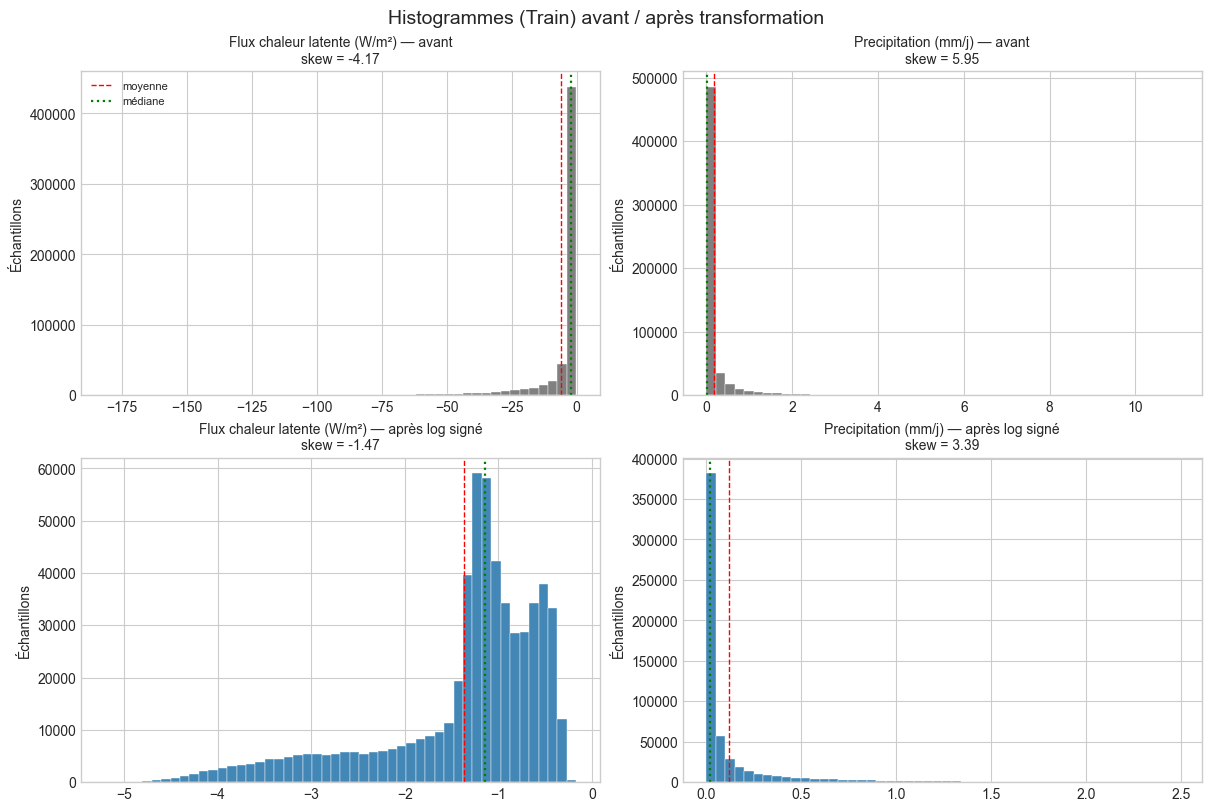

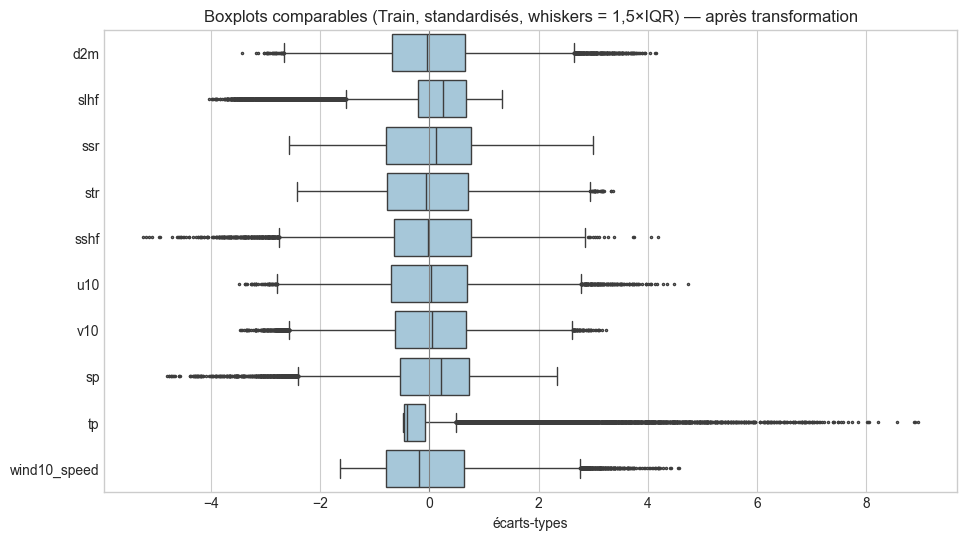

In [18]:
# ---- Histogrammes avant / après (même style que l'EDA : moyenne en rouge, médiane en vert) ----
k = max(len(TRANSFORM), 1)
fig, axes = plt.subplots(2, k, figsize=(6 * k, 8), constrained_layout=True, squeeze=False)
for j, v in enumerate(TRANSFORM):
    for i, (x, t) in enumerate([(train_raw[v], "avant"), (train[v], "après log signé")]):
        ax = axes[i, j]
        ax.hist(x, bins=50, color="#4287b5" if i else "grey", edgecolor="white", linewidth=.3)
        ax.axvline(x.mean(), color="red", ls="--", lw=1, label="moyenne"); ax.axvline(x.median(), color="green", ls=":", lw=1.6, label="médiane")
        ax.set_title(f"{LABELS[v]} — {t}\nskew = {stats.skew(x):.2f}", fontsize=10); ax.set_ylabel("Échantillons")
axes[0, 0].legend(fontsize=8)
fig.suptitle("Histogrammes (Train) avant / après transformation", fontsize=14); plt.show()

# ---- Boxplots comparables après transformation (le « avant » est dans l'EDA §2) ----
S = train.sample(min(40_000, len(train)), random_state=SEED).index
Za = (train.loc[S, FEATURES_KEPT] - train[FEATURES_KEPT].mean()) / train[FEATURES_KEPT].std()
plt.figure(figsize=(11, 6))
sns.boxplot(data=Za, orient="h", color="#9ecae1", fliersize=1.5, whis=1.5)
plt.axvline(0, color="grey", lw=.8); plt.title("Boxplots comparables (Train, standardisés, whiskers = 1,5×IQR) — après transformation")
plt.xlabel("écarts-types"); plt.show()

**Effet.** Pour les variables transformées, l'asymétrie diminue nettement et la variance Min-Max augmente : la « faible variabilité » relevée dans l'EDA était donc en grande partie un **effet d'échelle**, corrigé sans rien supprimer. Le pourcentage d'outliers IQR de `tp` et `slhf` reste élevé : c'est normal, une masse de valeurs proches de 0 ne peut pas être « symétrisée » par une transformation monotone (ce sont des variables intermittentes). Si une variable reste sous le seuil de 0,01 après transformation, on la garde quand même : l'EDA a montré que ce seuil dépend des unités, et `tp`/`slhf` renseignent sur l'humidité du sol et la nébulosité, qui modulent la température des semaines suivantes.

**Limites.** Le log dépend des unités (mm/j, W/m²) : c'est la raison pour laquelle on garde les unités physiques de l'EDA. Pour la Random Forest la transformation est sans effet (les arbres ne dépendent que de l'ordre des valeurs) et ne nuit pas.

## 8. Feature extraction : encodage cyclique du mois

**Problème.** Le mois est une feature du sujet. Codé de 1 à 12, il place décembre (12) et janvier (1) à la distance **maximale**, alors que ce sont deux mois d'hiver consécutifs. Pour un KNN ou un SVM, cette discontinuité déforme les voisinages précisément sur la variable qui porte le cycle saisonnier, principal moteur de la température du mois suivant.

**Méthode (cours 05 : fonctions trigonométriques).** `month_sin = sin(2π·m/12)`, `month_cos = cos(2π·m/12)` : les mois deviennent des points d'un cercle ; décembre et janvier sont voisins. Transformation sans paramètre → aucune fuite. Le mois brut est exporté en métadonnée (colonne `month`) mais n'est plus une feature : les deux colonnes cycliques portent la même information.

**Features dérivées retenues :** `wind10_speed` (§4) et `month_sin`/`month_cos`.

**Ce qu'on n'ajoute pas, et pourquoi** (ne pas multiplier les traitements) :
- *ACP* : une dizaine de features seulement, et les modèles (RF notamment) gagnent à garder les variables originales, interprétables ; l'ACP sert plutôt à la visualisation ;
- *t2m(M)* (persistance) : probablement la feature la plus prédictive, mais le sujet fixe la liste des features et ne l'inclut pas : à valider avec l'enseignante ;
- *lat / lon* : hors liste du sujet ; l'information spatiale principale (altitude) est déjà portée par `sp`. Elles sont exportées comme **métadonnées** pour pouvoir les ajouter plus tard.

**`year` : mise en garde.** Conservée car elle fait partie des features du sujet (interrupteur `USE_YEAR`). Avec un split chronologique, les années du Test sont **au-delà** de celles du Train : le modèle **extrapole** sur cette feature (un arbre la traite comme la dernière année vue ; un KNN standardisé voit toutes les lignes du Test loin des lignes du Train sur cet axe). À garder en tête dans l'interprétation, et à comparer avec `USE_YEAR = False` au moment de la modélisation.

13 features finales : ['d2m', 'slhf', 'ssr', 'str', 'sshf', 'u10', 'v10', 'sp', 'tp', 'wind10_speed', 'month_sin', 'month_cos', 'year']
[LOG] 8. Feature extraction → encodage cyclique du mois ; wind10_speed conservée


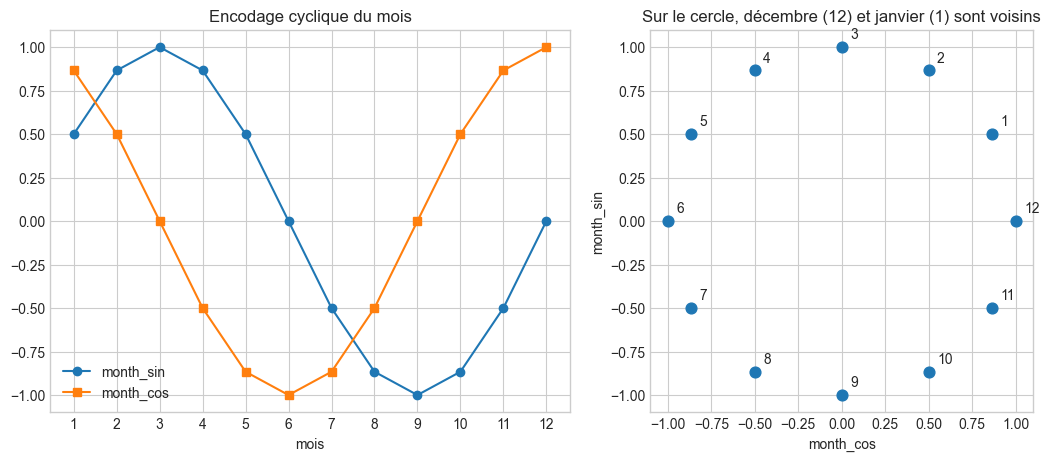

In [19]:
for part in (train, test):
    part["month_sin"] = np.sin(2 * np.pi * part["month"] / 12)
    part["month_cos"] = np.cos(2 * np.pi * part["month"] / 12)

FEATURES_FINAL = FEATURES_KEPT + ["month_sin", "month_cos"] + (["year"] if USE_YEAR else [])
print(f"{len(FEATURES_FINAL)} features finales :", FEATURES_FINAL)
log_step("8. Feature extraction", "encodage cyclique du mois ; wind10_speed conservée" if USE_WIND_SPEED else "encodage cyclique du mois",
         features_finales=FEATURES_FINAL, year_incluse=USE_YEAR)

m_ = np.arange(1, 13)
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5), constrained_layout=True)
ax[0].plot(m_, np.sin(2 * np.pi * m_ / 12), "o-", label="month_sin"); ax[0].plot(m_, np.cos(2 * np.pi * m_ / 12), "s-", label="month_cos")
ax[0].set_xlabel("mois"); ax[0].set_xticks(m_); ax[0].legend(); ax[0].set_title("Encodage cyclique du mois")
ax[1].scatter(np.cos(2 * np.pi * m_ / 12), np.sin(2 * np.pi * m_ / 12), s=60, color="tab:blue")
for k_ in m_: ax[1].annotate(str(k_), (np.cos(2 * np.pi * k_ / 12), np.sin(2 * np.pi * k_ / 12)), textcoords="offset points", xytext=(6, 6))
ax[1].set_aspect("equal"); ax[1].set_xlabel("month_cos"); ax[1].set_ylabel("month_sin"); ax[1].set_title("Sur le cercle, décembre (12) et janvier (1) sont voisins")
plt.show()

## 9. Discrétisation de la cible : 3 intervalles de même largeur

**Méthode imposée par le sujet :** *equal-width partitioning* (cours 04), avec W = (B − A) / 3, où A et B sont le minimum et le maximum de t2m(M+1).

**Ajustée sur le Train uniquement.** A et B sont calculés sur les cibles du **Train**, puis les **mêmes** bornes sont appliquées au Test : les calculer sur toute la période ferait dépendre la définition des classes des températures du Test. Une valeur du Test hors de [A, B] serait rangée dans la classe extrême correspondante (intervalles extérieurs ouverts).

**Pourquoi equal-width reste raisonnable ici.** Son défaut connu (cours 04) est d'être dominé par les outliers. L'EDA n'a trouvé **aucun outlier** sur `t2m` (0 % IQR, 0 % Z-score, skew ≈ −0,13) : les bornes ne sont pas tirées par des extrêmes.

**Différence avec l'EDA.** L'EDA avait calculé des bornes exploratoires sur toute la période ([0,91 ; 14,33 ; 27,74 ; 41,16] °C). Celles ci-dessous peuvent légèrement différer : c'est voulu (pas de fuite).

**Classes :** 0 = Froid, 1 = Modere, 2 = Chaud (variable **ordinale**, encodage entier ordonné, cours 05).

A = 0.91 °C, B = 41.16 °C, largeur W = (B − A)/3 = 13.41 °C


,classe,code,borne inf (°C),borne sup (°C)
0,Froid,0,0.91,14.33
1,Modere,1,14.33,27.74
2,Chaud,2,27.74,41.16


Test hors de [A, B] : 0 sous A, 0 au-dessus de B (0.000 % du Test)
[LOG] 9. Discrétisation → equal-width, 3 classes, bornes calculées sur le Train


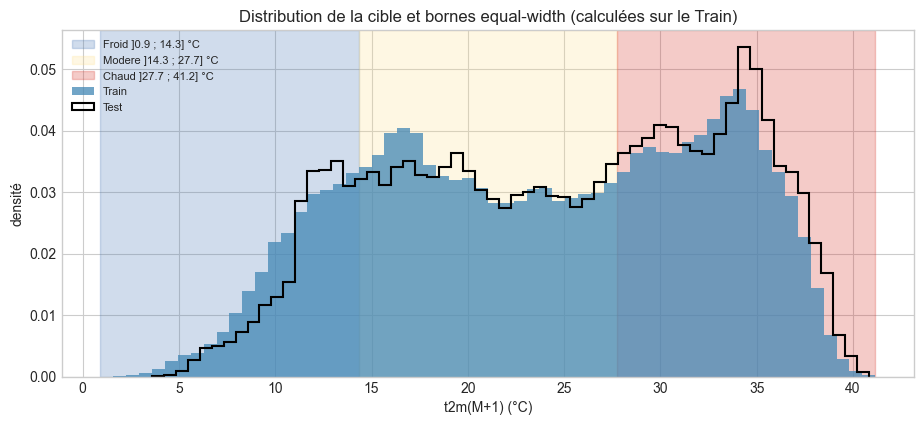

In [20]:
A, B = float(train["t2m_next"].min()), float(train["t2m_next"].max())
W = (B - A) / 3
EDGES = [A, A + W, A + 2 * W, B]
bins = [-np.inf, EDGES[1], EDGES[2], np.inf]

for part in (train, test):
    part["target_class"] = pd.cut(part["t2m_next"], bins=bins, labels=[0, 1, 2], right=True).astype(int)
    part["target_label"] = part["target_class"].map(dict(enumerate(CLASS_LABELS)))

print(f"A = {A:.2f} °C, B = {B:.2f} °C, largeur W = (B − A)/3 = {W:.2f} °C")
display(pd.DataFrame({"classe": CLASS_LABELS, "code": [0, 1, 2], "borne inf (°C)": np.round(EDGES[:-1], 2), "borne sup (°C)": np.round(EDGES[1:], 2)}))
out_lo, out_hi = int((test["t2m_next"] < A).sum()), int((test["t2m_next"] > B).sum())
print(f"Test hors de [A, B] : {out_lo} sous A, {out_hi} au-dessus de B ({100 * (out_lo + out_hi) / len(test):.3f} % du Test)")
log_step("9. Discrétisation", "equal-width, 3 classes, bornes calculées sur le Train", bornes=[round(e, 3) for e in EDGES], largeur=round(W, 3))

COLORS = {"Froid": "#4575b4", "Modere": "#fee090", "Chaud": "#d73027"}
fig, ax = plt.subplots(figsize=(11, 4.5))
for lab, lo_, hi_ in zip(CLASS_LABELS, EDGES[:-1], EDGES[1:]):
    ax.axvspan(lo_, hi_, color=COLORS[lab], alpha=.25, label=f"{lab} ]{lo_:.1f} ; {hi_:.1f}] °C")
ax.hist(train["t2m_next"], bins=60, density=True, color="#4287b5", alpha=.75, label="Train")
ax.hist(test["t2m_next"], bins=60, density=True, histtype="step", color="k", lw=1.5, label="Test")
ax.set_xlabel("t2m(M+1) (°C)"); ax.set_ylabel("densité"); ax.set_title("Distribution de la cible et bornes equal-width (calculées sur le Train)"); ax.legend(fontsize=8)
plt.show()

## 10. Analyse des effectifs et des pourcentages des classes

,Train (n),Train (%),Test (n),Test (%)
classe,,,,
Froid,102139,17.60,27308,15.26
Modere,251697,43.37,75632,42.25
Chaud,226532,39.03,76052,42.49


Rapport classe majoritaire / minoritaire : Train 2.46 | Test 2.78 — classe minoritaire (Train) : Froid


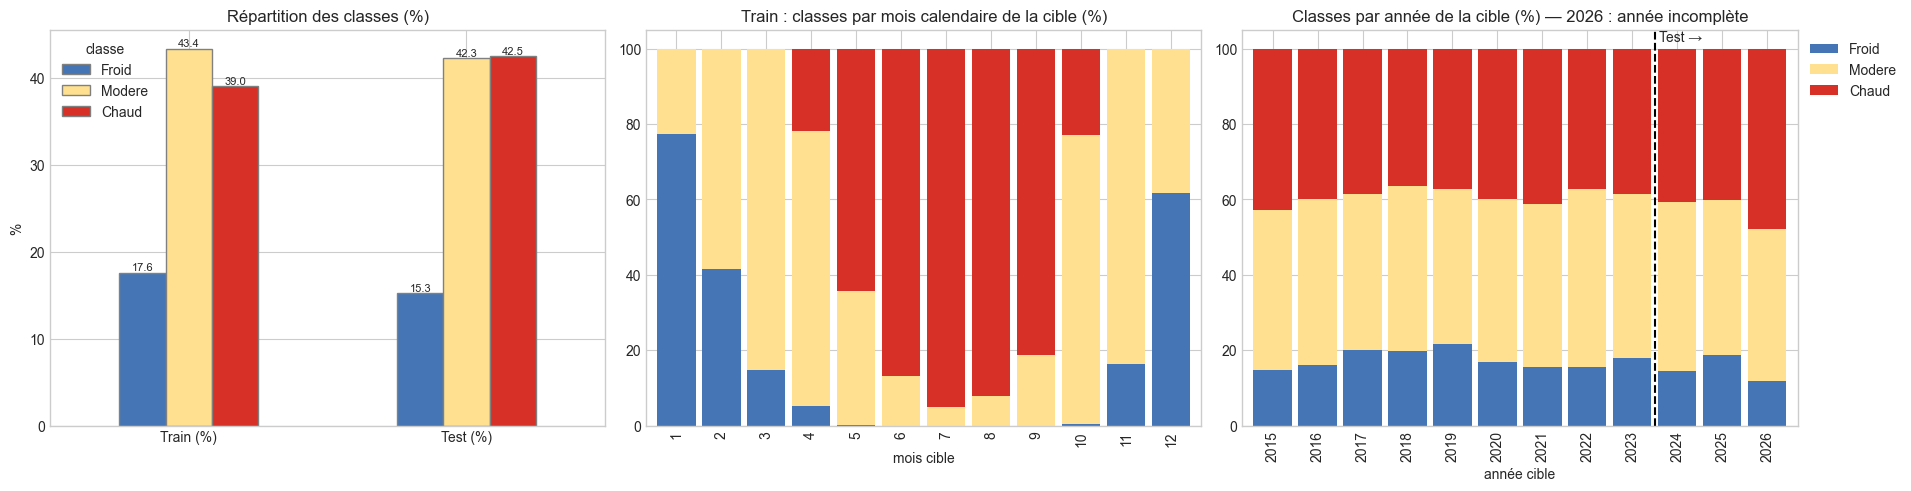

Train : % de chaque classe selon la saison du mois cible


target_label,Froid,Modere,Chaud
target_time,,,
Hiver,59.5,40.5,0.0
Printemps,6.8,64.5,28.7
Été,0.0,8.7,91.3
Automne,5.6,59.7,34.7


[LOG] 10. Classes → analyse des effectifs


In [21]:
cnt_tr = train["target_label"].value_counts().reindex(CLASS_LABELS)
cnt_te = test["target_label"].value_counts().reindex(CLASS_LABELS)
dist = pd.DataFrame({"Train (n)": cnt_tr, "Train (%)": 100 * cnt_tr / cnt_tr.sum(), "Test (n)": cnt_te, "Test (%)": 100 * cnt_te / cnt_te.sum()})
dist.index.name = "classe"
display(dist.round(2))
imb = dist["Train (%)"].max() / dist["Train (%)"].min()
imb_te = dist["Test (%)"].max() / dist["Test (%)"].min()
print(f"Rapport classe majoritaire / minoritaire : Train {imb:.2f} | Test {imb_te:.2f} — classe minoritaire (Train) : {dist['Train (%)'].idxmin()}")

fig, axes = plt.subplots(1, 3, figsize=(19, 4.8), constrained_layout=True)
dist[["Train (%)", "Test (%)"]].T.plot.bar(ax=axes[0], color=[COLORS[l] for l in CLASS_LABELS], rot=0, edgecolor="grey")
for cont in axes[0].containers: axes[0].bar_label(cont, fmt="%.1f", fontsize=8)
axes[0].set_title("Répartition des classes (%)"); axes[0].set_ylabel("%")
pm = pd.crosstab(train["target_time"].dt.month, train["target_label"], normalize="index").reindex(columns=CLASS_LABELS, fill_value=0) * 100
pm.plot.bar(stacked=True, ax=axes[1], color=[COLORS[l] for l in CLASS_LABELS], width=.85, legend=False)
axes[1].set_title("Train : classes par mois calendaire de la cible (%)"); axes[1].set_xlabel("mois cible")
both = pd.concat([train, test])
py = pd.crosstab(both["target_time"].dt.year, both["target_label"], normalize="index").reindex(columns=CLASS_LABELS, fill_value=0) * 100
py.plot.bar(stacked=True, ax=axes[2], color=[COLORS[l] for l in CLASS_LABELS], width=.85)
axes[2].axvline(py.index.get_loc(SPLIT_TARGET.year) - .5, color="k", lw=1.5, ls="--"); axes[2].text(py.index.get_loc(SPLIT_TARGET.year) - .4, 102, "Test →")
axes[2].set_title("Classes par année de la cible (%) — 2026 : année incomplète"); axes[2].set_xlabel("année cible"); axes[2].legend(loc="upper left", bbox_to_anchor=(1, 1))
plt.show()

SEASON = {12: "Hiver", 1: "Hiver", 2: "Hiver", 3: "Printemps", 4: "Printemps", 5: "Printemps", 6: "Été", 7: "Été", 8: "Été", 9: "Automne", 10: "Automne", 11: "Automne"}
by_season = (pd.crosstab(train["target_time"].dt.month.map(SEASON), train["target_label"], normalize="index")
             .reindex(index=["Hiver", "Printemps", "Été", "Automne"], columns=CLASS_LABELS, fill_value=0) * 100).round(1)
print("Train : % de chaque classe selon la saison du mois cible"); display(by_season)
log_step("10. Classes", "analyse des effectifs", train=cnt_tr.astype(int).to_dict(), test=cnt_te.astype(int).to_dict(), ratio_train=round(float(imb), 2), ratio_test=round(float(imb_te), 2))

**Lecture et conséquences pour le supervised learning.**
- **Déséquilibre attendu.** Avec des intervalles de même largeur, les classes n'ont pas le même effectif : les bornes suivent l'échelle de température, pas la fréquence des valeurs (inconvénient de l'*equal-width* signalé au cours 04). La classe « Froid » est la minoritaire : mois d'hiver des Hauts Plateaux et de l'Atlas, le Sahara n'y entre presque jamais (cohérent avec l'EDA : ≈ 17 %).
- **La classe dépend très fortement de la saison** (graphique central et tableau). Le mois est donc une feature essentielle, ce qui justifie son encodage cyclique (§8).
- **Train et Test diffèrent** : le Test (2024-2026) est plus récent, plus chaud, et ne compte que 2,75 années (l'hiver 2026-27 n'y figure pas). C'est un *shift* réaliste, conséquence normale d'un split chronologique : on ne le « corrige » pas, on l'**évalue**.
- **Ce qu'on ne fait pas ici :** on ne rééquilibre pas les classes. Sur-/sous-échantillonnage (SMOTE…) sont des choix de **modélisation**, à appliquer **sur le Train uniquement** ; le Test garde sa distribution réelle.
- **Pour la suite :** l'accuracy seule serait trompeuse → rapporter **F1 macro**, **balanced accuracy** et la **matrice de confusion** ; `class_weight="balanced"` pour SVM et Random Forest ; vote pondéré par la distance pour KNN ; réglage des hyperparamètres par `TimeSeriesSplit` sur le Train.

## 11. Feature scaling

**Pourquoi.** KNN et SVM reposent sur des distances / produits scalaires. Sans mise à l'échelle, `sp` (≈ 950 hPa, σ ≈ 33) écraserait `month_cos` (σ ≈ 0,7) dans les distances (cours 05, remarque du cours 06 sur le KNN).

**Méthode : standardisation** (moyenne 0, écart-type 1), plutôt que :
- **Min-Max** : sensible aux extrêmes (cours 05) ; or on a volontairement **conservé** les extrêmes climatiques, et le Test sort de l'étendue du Train pour certaines variables (années plus chaudes) → des valeurs > 1 apparaîtraient ;
- **Robust scaler** : non détaillé dans le cours ; après le log signé, les distributions restantes ne justifient plus un changement de méthode.

**Sans fuite.** Le scaler est **ajusté sur le Train** (`fit`), puis appliqué tel quel au Test (`transform`). Le Test n'a donc pas exactement une moyenne de 0 et un écart-type de 1 : un écart notable signale simplement un changement de distribution entre périodes (par construction pour `year`).

,moyenne Train (fit),écart-type Train (fit),moyenne Train après,std Train après,moyenne Test après,std Test après
d2m,1.390,4.822,0.0,1.0,0.096,0.994
slhf,-1.370,0.891,-0.0,1.0,-0.038,1.020
ssr,167.048,42.558,0.0,1.0,-0.015,0.996
str,-117.172,22.555,-0.0,1.0,0.011,1.015
sshf,-41.393,21.762,0.0,1.0,-0.021,1.047
u10,-1.033,1.600,0.0,1.0,0.036,0.968
v10,-0.513,1.042,-0.0,1.0,0.003,1.017
sp,951.763,33.526,-0.0,1.0,-0.001,1.000
tp,0.120,0.251,0.0,1.0,0.042,1.057
wind10_speed,1.908,1.158,-0.0,1.0,-0.050,0.989


Train standardisé (moyenne 0, écart-type 1) ✔ — Test transformé avec les paramètres du Train ✔
⚠ year : moyenne Test standardisée = 2.28 σ → le Test est hors de l'étendue d'entraînement sur cette feature (voir §8).


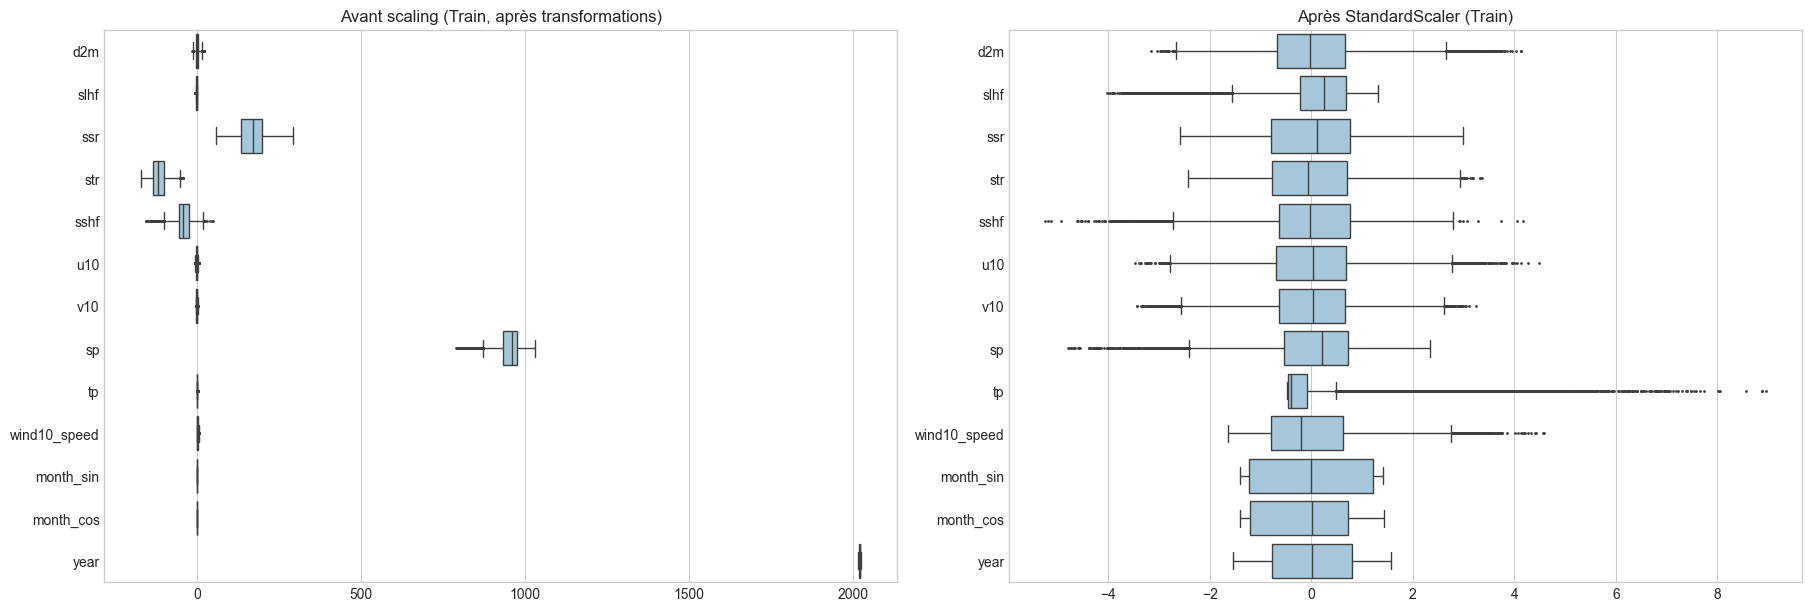

[LOG] 11. Scaling → StandardScaler ajusté sur le Train


In [22]:
scaler = StandardScaler().fit(train[FEATURES_FINAL])
train_s, test_s = train.copy(), test.copy()
train_s[FEATURES_FINAL] = scaler.transform(train[FEATURES_FINAL])
test_s[FEATURES_FINAL] = scaler.transform(test[FEATURES_FINAL])

sc = pd.DataFrame({"moyenne Train (fit)": scaler.mean_, "écart-type Train (fit)": scaler.scale_,
                   "moyenne Train après": train_s[FEATURES_FINAL].mean().values, "std Train après": train_s[FEATURES_FINAL].std(ddof=0).values,
                   "moyenne Test après": test_s[FEATURES_FINAL].mean().values, "std Test après": test_s[FEATURES_FINAL].std(ddof=0).values}, index=FEATURES_FINAL)
display(sc.round(3))
assert np.allclose(train_s[FEATURES_FINAL].mean(), 0, atol=1e-6) and np.allclose(train_s[FEATURES_FINAL].std(ddof=0), 1, atol=1e-6)
print("Train standardisé (moyenne 0, écart-type 1) ✔ — Test transformé avec les paramètres du Train ✔")
if "year" in FEATURES_FINAL:
    print(f"⚠ year : moyenne Test standardisée = {sc.loc['year', 'moyenne Test après']:.2f} σ → le Test est hors de l'étendue d'entraînement sur cette feature (voir §8).")

S = train.sample(min(30_000, len(train)), random_state=SEED).index
fig, axes = plt.subplots(1, 2, figsize=(18, 6), constrained_layout=True)
sns.boxplot(data=train.loc[S, FEATURES_FINAL], orient="h", ax=axes[0], fliersize=1, color="#9ecae1"); axes[0].set_title("Avant scaling (Train, après transformations)")
sns.boxplot(data=train_s.loc[S, FEATURES_FINAL], orient="h", ax=axes[1], fliersize=1, color="#9ecae1"); axes[1].set_title("Après StandardScaler (Train)")
plt.show()
log_step("11. Scaling", "StandardScaler ajusté sur le Train")

## 12. Export du dataset pour le supervised learning

Fichiers écrits dans `data/supervisedvfin/` (variable `OUT_DIR`) (les fichiers d'origine ne sont pas modifiés) :

| Fichier | Contenu |
|---|---|
| `supervised_train.csv`, `supervised_test.csv` | métadonnées (`time`, `target_time`, `cell`, `lat`, `lon`, `month`, `anomaly_corrected`) · **features standardisées** · `target_class` (0/1/2) · `target_label` · `t2m_next_C` (valeur continue en °C, **référence uniquement, ne pas utiliser comme feature**) |
| `scaler.joblib` | le `StandardScaler` ajusté sur le Train |
| `preprocessing_params.json` | tout ce qui a été décidé ou appris : mois et facteur de correction, features supprimées et raisons, variables transformées, bornes des classes, moyenne et écart-type du scaler, liste ordonnée des features, journal des décisions |

**Utilisation :** `X = df[params["feature_columns"]]`, `y = df["target_class"]`. Les valeurs non standardisées s'obtiennent par `x = z · scale + mean`. La Random Forest peut utiliser les features standardisées : les arbres ne dépendent que de l'ordre des valeurs. Les colonnes de métadonnées (`lat`, `lon`, `cell`, `time`, `month`, `anomaly_corrected`) servent aux cartes et à l'analyse d'erreurs, **jamais comme features**.

In [23]:
META = ["time", "target_time", "cell", "lat", "lon", "month", "anomaly_corrected"]
TARGETS = ["target_class", "target_label", "t2m_next_C"]
def export(part, name):
    out = part.rename(columns={"t2m_next": "t2m_next_C"})[META + FEATURES_FINAL + TARGETS]
    out.to_csv(OUT_DIR / name, index=False, float_format="%.6g", date_format="%Y-%m-%d")
    return out
exp_train, exp_test = export(train_s, "supervised_train.csv"), export(test_s, "supervised_test.csv")
joblib.dump(scaler, OUT_DIR / "scaler.joblib")

params = {
    "cree_le": datetime.now().isoformat(timespec="seconds"),
    "source_file": str(DATA_REL).replace("\\", "/"),
    "interrupteurs": {"USE_WIND_SPEED": USE_WIND_SPEED, "USE_YEAR": USE_YEAR, "MANUAL_DROP": MANUAL_DROP},
    "era5land_known_issue": {"months_corrected": [d.strftime("%Y-%m") for d in AFFECTED], "variables": ACCUMULATED, "factor": FACTOR,
                             "factor_estimated_ssr_str": round(f_est, 4), "estimation_months": [d.strftime("%Y-%m") for d in est_months],
                             "reference_climatology_years": list(REF_YEARS)},
    "physical_clipping": "tp, ro clipped at 0",
    "split": {"rule": "target month < 2024-01 -> train ; >= 2024-01 -> test", "train_rows": len(train), "test_rows": len(test)},
    "correlation_formula": CORR_METHOD,
    "dropped_features": REASONS,
    "signed_log_transformed": TRANSFORM,
    "feature_columns": FEATURES_FINAL,
    "metadata_columns": META,
    "target": {"column": "target_class", "labels": dict(enumerate(CLASS_LABELS)), "method": "equal-width, 3 bins, fitted on train",
               "edges_C": [float(e) for e in EDGES], "outer_bins_open": True},
    "scaler": {"type": "StandardScaler (fit on train)", "mean": dict(zip(FEATURES_FINAL, scaler.mean_.round(6).tolist())),
               "scale": dict(zip(FEATURES_FINAL, scaler.scale_.round(6).tolist()))},
    "class_distribution_pct": {"train": dist["Train (%)"].round(3).to_dict(), "test": dist["Test (%)"].round(3).to_dict()},
    "journal": LOG}
with open(OUT_DIR / "preprocessing_params.json", "w", encoding="utf-8") as fh:
    json.dump(params, fh, ensure_ascii=False, indent=2, default=str)
for f in ["supervised_train.csv", "supervised_test.csv", "scaler.joblib", "preprocessing_params.json"]:
    print(f"{f:28s} {(OUT_DIR / f).stat().st_size / 1e6:8.2f} Mo")

supervised_train.csv           103.82 Mo
supervised_test.csv             31.81 Mo
scaler.joblib                    0.00 Mo
preprocessing_params.json        0.01 Mo


## 13. Vérifications finales (relecture des fichiers exportés)

In [24]:
P = json.load(open(OUT_DIR / "preprocessing_params.json", encoding="utf-8"))
tr = pd.read_csv(OUT_DIR / "supervised_train.csv", parse_dates=["time", "target_time"])
te = pd.read_csv(OUT_DIR / "supervised_test.csv", parse_dates=["time", "target_time"])
F, E = P["feature_columns"], P["target"]["edges_C"]
allp = pd.concat([tr, te])
cls_from_edges = pd.cut(allp["t2m_next_C"], [-np.inf, E[1], E[2], np.inf], labels=[0, 1, 2]).astype(int).values
near_edge = np.min(np.abs(allp["t2m_next_C"].values[:, None] - np.array(E[1:3])), axis=1) < 1e-3     # le CSV arrondit à 6 chiffres significatifs

checks = {
    "colonnes identiques Train/Test": list(tr.columns) == list(te.columns),
    "aucune valeur manquante": int(tr.isna().sum().sum() + te.isna().sum().sum()) == 0,
    "nb de lignes = cellules × mois": len(tr) == N * tr["time"].nunique() and len(te) == N * te["time"].nunique(),
    "pas de doublon (cellule, mois)": not tr.duplicated(["cell", "time"]).any() and not te.duplicated(["cell", "time"]).any(),
    "cible = mois suivant": bool(((tr["target_time"] - tr["time"]).dt.days.between(28, 31)).all() and ((te["target_time"] - te["time"]).dt.days.between(28, 31)).all()),
    "Train strictement antérieur au Test": tr["target_time"].max() < te["target_time"].min() and tr["time"].max() < te["time"].min(),
    "aucune feature interdite (t2m, cible, lat/lon, supprimées)": set(F).isdisjoint({"t2m", "t2m_next_C", "target_class", "target_label", "lat", "lon", "cell", "time", *P["dropped_features"]}),
    "scaler ajusté sur le Train": bool(np.allclose(tr[F].mean(), 0, atol=1e-3) and np.allclose(tr[F].std(ddof=0), 1, atol=1e-3)),
    "scaler.joblib reproduit les features exportées": bool(np.allclose(joblib.load(OUT_DIR / "scaler.joblib").transform(train[F].iloc[:1000]), tr[F].iloc[:1000].values, atol=1e-3)),
    "bornes = equal-width du Train": bool(np.isclose(tr["t2m_next_C"].min(), E[0], atol=1e-3) and np.isclose(tr["t2m_next_C"].max(), E[3], atol=1e-3)
                                          and np.allclose(np.diff(E), np.diff(E)[0], atol=1e-3)),
    "classes cohérentes avec les bornes": bool(((cls_from_edges == allp["target_class"].values) | near_edge).all()),
    "3 classes présentes dans Train et Test": tr["target_class"].nunique() == 3 and te["target_class"].nunique() == 3,
}
res = pd.Series(checks, name="OK"); display(res.to_frame())
assert res.all(), "Au moins une vérification a échoué"
print(f"Toutes les vérifications passent ✔  |  Train {tr.shape} · Test {te.shape} · {len(F)} features")

,OK
colonnes identiques Train/Test,True
aucune valeur manquante,True
nb de lignes = cellules × mois,True
"pas de doublon (cellule, mois)",True
cible = mois suivant,True
Train strictement antérieur au Test,True
"aucune feature interdite (t2m, cible, lat/lon, supprimées)",True
scaler ajusté sur le Train,True
scaler.joblib reproduit les features exportées,True
bornes = equal-width du Train,True


Toutes les vérifications passent ✔  |  Train (580368, 23) · Test (178992, 23) · 13 features


## Synthèse des décisions (à reprendre dans le rapport)

| Problème (EDA) | Décision | Justification principale |
|---|---|---|
| NaN frontière nord | Aucune imputation ; cellules sans donnée exclues du domaine | Points hors domaine terrestre ERA5-Land (pas de vraies valeurs manquantes) ; 0 NaN dans le domaine ; imputation spatiale 3×3 prévue en secours seulement |
| Incohérences 2022-2024 | Variables accumulées × 2 sur sept. 2022 → févr. 2024 | *Known issue* ECMWF ; erreur de source, pas un signal climatique ; facteur estimé sur des mois du Train ; vérifié par z-scores, rapports et Q-Q plots |
| Outliers / asymétrie | Aucune suppression ; contrôle physique ; **log signé** si \|skew\| > 1 (décidé sur le Train) | Extrêmes réels (réanalyse) ; les queues lourdes nuisent aux modèles à distance |
| Faible variabilité | `ro` supprimée ; `slhf`, `tp` conservées (effet d'échelle corrigé par le log) ; `sp` conservée | Quasi-constance de `ro` ; `sp` = proxy d'altitude (variabilité spatiale) |
| Corrélations (Spearman) | `e` supprimée ; `ro` supprimée ; `ssr` et `sshf` conservées | slhf = ρ·L_v·e ; `ssr`–`sshf` corrélées par la saison seulement (anomalies faiblement corrélées) |
| Cible | t2m(M+1) de la même cellule ; 3 classes equal-width ajustées sur le Train | Consigne du sujet ; aucune fuite |
| Split | Chronologique sur le mois cible (≤ déc. 2023 / ≥ janv. 2024) | Prévision ; aucun chevauchement temporel |
| Features | variables retenues + `wind10_speed` + `month_sin`, `month_cos` (+ `year`) | Encodage cyclique pour les modèles à distance ; mise en garde sur `year` |
| Scaling | StandardScaler ajusté sur le Train | Égalise le poids des features en distance ; robuste aux extrêmes conservés |

In [25]:
recap = pd.DataFrame([{"étape": e["etape"], "décision": e["decision"]} for e in LOG])
print(recap.to_string(index=False))

                     étape                                                    décision
     1. Valeurs manquantes aucune imputation ; cellules sans donnée exclues du domaine
 2. Incohérences 2022-2024  variables accumulées × 2.0 sur 18 mois (2022-09 → 2024-02)
     3. Cohérence physique                       aucune suppression ; tp/ro bornés à 0
                  4. Cible           t2m(M+1) de la même cellule ; dernier mois retiré
                  5. Split         chronologique sur le mois cible (< 2024-01 → Train)
6.1 Formule de corrélation    Spearman (conclusion EDA §5.1 : aucune variable normale)
              6. Sélection                                      retirées : ['e', 'ro']
              7. Asymétrie                                 log signé de ['slhf', 'tp']
     8. Feature extraction          encodage cyclique du mois ; wind10_speed conservée
         9. Discrétisation       equal-width, 3 classes, bornes calculées sur le Train
               10. Classes                 

**Utilisation dans le notebook suivant :**
```python
import json, pandas as pd
D = "data/supervisedvfin/"
P = json.load(open(D + "preprocessing_params.json", encoding="utf-8"))
train = pd.read_csv(D + "supervised_train.csv", parse_dates=["time", "target_time"])
test  = pd.read_csv(D + "supervised_test.csv",  parse_dates=["time", "target_time"])
X_train, y_train = train[P["feature_columns"]], train["target_class"]
X_test,  y_test  = test[P["feature_columns"]],  test["target_class"]
```